In [2]:
# get data from: https://www.frontiersin.org/journals/psychology/articles/10.3389/fpsyg.2022.1039172/full#h16

import pandas as pd

df = pd.read_csv("data/empdata1.csv")
df

,cond,response,rt
0,s1,lower,0.437543
1,s1,lower,0.478732
2,s1,lower,0.352887
3,s1,lower,0.346259
4,s1,lower,0.256688
...,...,...,...
495,s2,upper,0.406501
496,s2,upper,0.482574
497,s2,upper,0.463195
498,s2,upper,0.466468


In [37]:
df

,plausible,response,rt
0,s1,-1,437.0
1,s1,-1,478.0
2,s1,-1,352.0
3,s1,-1,346.0
4,s1,-1,256.0
...,...,...,...
495,s2,1,406.0
496,s2,1,482.0
497,s2,1,463.0
498,s2,1,466.0


In [4]:
df.rename(columns={"cond": "plausible",}, inplace=True)

In [13]:
df.loc[df["response"]=="lower","response"]=-1
df.loc[df["response"]=="upper","response"]=1

In [36]:
df.loc[:,"rt"]=(df["rt"]*1000).astype("int")

In [ ]:
  def plot_histogram(self, conditions=[-1,0,1], normalize="absolute", title=None):
  def __init__(self, z0, drift, noise, nrt, betas, dependent_variable, conditions=["RainDropDown", "Neutral", "RainDropUp"], t_upper=1, t_lower=0, max_timesteps=1000):


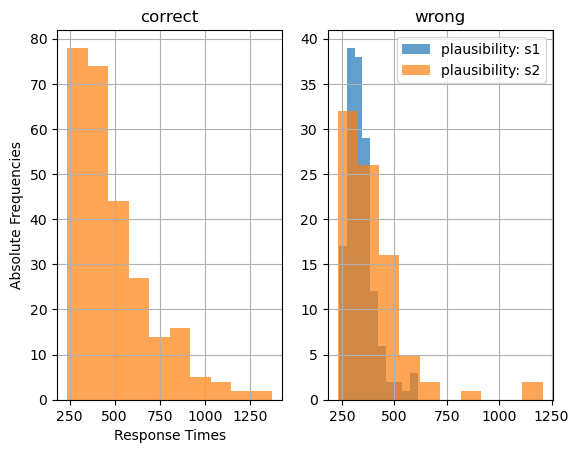

In [38]:
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
ddm.plot_histogram(conditions=["s1", "s2"])

In [40]:
a=[1,2,3]
print(a.pop())
print(a)

3
[1, 2]


In [ ]:
#old
def sumation(self.constants, self.free_params, x):
    return np.sum(self.constants, self.free_params, x)

def sum_back(self.constants, self.free_params, x):
    """
    I think we should only do derivatives when there is something going on...
    """
    

In [61]:
{"A":1,}.keys()

dict_keys(['A'])

In [80]:
help(dict)

Help on class dict in module builtins:

class dict(object)
 |  dict() -> new empty dictionary
 |  dict(mapping) -> new dictionary initialized from a mapping object's
 |      (key, value) pairs
 |  dict(iterable) -> new dictionary initialized as if via:
 |      d = {}
 |      for k, v in iterable:
 |          d[k] = v
 |  dict(**kwargs) -> new dictionary initialized with the name=value pairs
 |      in the keyword argument list.  For example:  dict(one=1, two=2)
 |  
 |  Built-in subclasses:
 |      StgDict
 |  
 |  Methods defined here:
 |  
 |  __contains__(self, key, /)
 |      True if the dictionary has the specified key, else False.
 |  
 |  __delitem__(self, key, /)
 |      Delete self[key].
 |  
 |  __eq__(self, value, /)
 |      Return self==value.
 |  
 |  __ge__(self, value, /)
 |      Return self>=value.
 |  
 |  __getattribute__(self, name, /)
 |      Return getattr(self, name).
 |  
 |  __getitem__(...)
 |      x.__getitem__(y) <==> x[y]
 |  
 |  __gt__(self, value, /)
 |  

# Architecture

In [1]:
class Node:
    def __init__(self, free_params, constants, operation, derivative):
        self.free_params_dict=dict(zip(free_params,np.arange(len(free_params))))
        self.free_params=np.array(list(free_params.values()))
        self.constants=constants
        self.memory=[]
        self.operation=operation
        self.derivative=derivative
        self.gradients=[]
        
    def forward(self,x):
        self.memory.append(x)
        return self.operation(self.constants, self.free_params, x)
    
    def back(self, df, t=None):
        """
        params:
            df (float): gradient of the next operation aka derivative of all that happens after this node
        """
        x=self.memory[t]
        #x=self.memory.pop()
        self.gradients.append(self.derivative(self.constants, self.free_params, x, df))
        return self.gradients[-1]
    
    def update(self, lr, v=False):
        """
        terrible efficiency, todo: use dict only for mapping index to name and work on an array
        """
        #for key in np.arange(len(self.free_params)):
        #print(self.gradients)
        self.free_params-=lr*np.sum(self.gradients, axis=0)
        if v:
            print(lr*np.sum(self.gradients, axis=0))
        self.gradients=[]
    

In [2]:
def ddm_forward(constants, free_params, x):
    """
    expects x[0]=z and x[1]=noise
    """
    #print(f"{x[0]}+{x[1]}*{free_params[0]}+{free_params[1]}")
    return x[0]+x[1]*free_params[0]+free_params[1]

def ddm_backward(constants, free_params, x, df):
    """
    should give deriatives wrt z, drift and noise, nrt has to be somehow included in the loss function
    df (float): derivative of previous functions
    """
    #print(df, x)
    #return df*1, df*1, df*x[1] so far no z0
    return df*x[1], df*1

def l2_forward(_, __, x):
    """
    x[0]=y, x[1]=true (convention: inputs first, constants last)
    """
    return 1/2*(x[0]-x[1])**2

def l2_backward(_, __, x, ___):
    """
    gotta give gradient wrt input
    """
    return x[0]-x[1]

# Test training after one iteration

In [140]:
sigma=0.4
drift=0.8

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backwards)

In [126]:
z0=0.5
def generate_data(model, n=100):
    data=np.zeros((n,))
    
    for i in range(n):
        data[i]=model.forward([z0, np.random.random()-0.5])
        
    return data

print(generate_data(ddm_net))

[1.20155037 1.15902519 1.29739059 1.46967489 1.12229465 1.23737061
 1.44342158 1.45405755 1.36553133 1.40472914 1.4023621  1.39690213
 1.47791964 1.19294809 1.25769428 1.32304945 1.46095756 1.25666653
 1.26237192 1.49663703 1.24018687 1.12718738 1.17016592 1.3212127
 1.25460818 1.4199906  1.17654016 1.37974258 1.20536413 1.23139654
 1.45574375 1.1419589  1.17076508 1.4787268  1.49966265 1.12240364
 1.34668136 1.40035386 1.29488394 1.40100867 1.10538175 1.23266451
 1.1967058  1.12367103 1.38576478 1.25497823 1.34779944 1.19501311
 1.35243066 1.35283598 1.35595967 1.24678692 1.33624539 1.24439532
 1.21835749 1.38648399 1.2093304  1.19864726 1.45458225 1.28505845
 1.47423963 1.16067103 1.10182356 1.16939164 1.28525443 1.26520417
 1.11916366 1.40463778 1.40445466 1.13501733 1.47878799 1.32509657
 1.1791358  1.21745797 1.28753475 1.33624054 1.26740685 1.27098314
 1.44479203 1.38501656 1.13679438 1.13276202 1.48301838 1.38619731
 1.38830381 1.28995436 1.15660007 1.16839461 1.40191077 1.43541

original params:
  sigma: 0.4
  drift: 0.8

init params:
  sigma: 0.22722778989323278
  drift: -0.4998283256401056

train params:
  sigma: 0.28020220861608475
  drift: -0.3886267874287764

train params:
  sigma: 0.3634717318190628
  drift: 0.6009202742049633

train params:
  sigma: 0.18734335387601037
  drift: 0.6962433372692878

train params:
  sigma: 0.09550696188424015
  drift: 0.7434809998922919

train params:
  sigma: 0.051460363084351826
  drift: 0.7673510328988649

train params:
  sigma: 0.02606316830523402
  drift: 0.7806132778041555

train params:
  sigma: 0.011183063928815786
  drift: 0.787394410659254

train params:
  sigma: 0.005445295301609511
  drift: 0.7908440460671725

train params:
  sigma: 0.003749971894678469
  drift: 0.7918320890768767

train params:
  sigma: 0.0018815077145293198
  drift: 0.7933194028588879



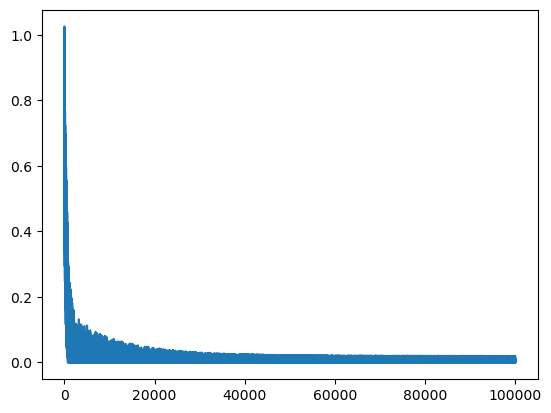

In [128]:
import matplotlib.pyplot as plt

epochs=1000

#true model

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backwards)

train_data=generate_data(ddm_net)

print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backwards)
loss_function=Node({},{},l2_forward,l2_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]

for epoch in range(epochs):
    for true in train_data:
        y = train_model.forward([z0, np.random.random()])#for now lets not train z0
        losses.append(loss_function.forward([y, true]))
        d_activation=loss_function.back(None)
        _=train_model.back(d_activation)
        train_model.update(0.001)
    losses_smooth.append(np.mean(losses[-len(train_data):]))
    if not epoch%(epochs/10):
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

plt.plot(np.arange(len(losses)), losses)
plt.show()
# qed! nice :D

# Maximize rewards over time

In [6]:
# nr = negative reward, preliminary name for new update

def nr_forward(_, __, x):
    """
    x[0]=y, x[1]=t,pos , x[2]=t,neg (convention: inputs first, constants last)
    """
    return -(x[0]*x[1]+(1-x[0])*x[2])

'''
f=-(x[0]*x[1]+(1-x[0])*x[2])
f=-x[0]*x[1]-(1-x[0])*x[2]
f=-x[0]*x[1]-(x[2]-x[0]*x[2])

a=-x[0]*x[1]
b=-x[2]+x[0]*x[2]

sum rule:
df/dx[0] = da/dx[0] + db/dx[0]
da/dx[0] = -x[1]
db/dx[0] = x[2]
'''

def nr_backward(_, __, x, ___):
    """
    gotta give gradient wrt input
    """
    return -x[1]+x[2]


def weighted_distance(_, __, x):
    """
    nope
    """
    return (1-x[0])*x[1]+x[0]*x[2]

In [13]:
1.1**10

2.5937424601000023

In [14]:
0.9**10

0.3486784401000001

In [5]:

import warnings
warnings.filterwarnings("error")

import numpy as np
import pandas as pd
from tqdm import tqdm

     response    rt
0         1.0  13.0
1         1.0  30.0
2        -1.0   9.0
3         1.0  10.0
4         1.0  20.0
..        ...   ...
995      -1.0   8.0
996       1.0  18.0
997       1.0  77.0
998       1.0  92.0
999      -1.0  15.0

[1000 rows x 2 columns]


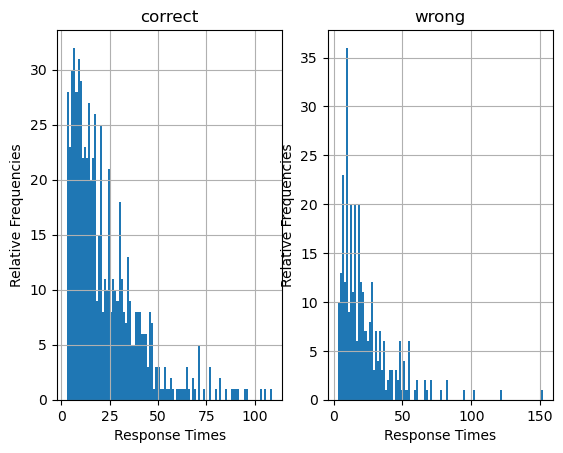

original params:
  sigma: 0.4
  drift: 0.01

init params:
  sigma: 0.48548635305127275
  drift: -0.46401830616052797



 33%|█████████████████████████▌                                                   | 332/1000 [00:00<00:00, 3245.56it/s]

train params:
  sigma: 0.5014005073840675
  drift: -0.4393857458758042

train params:
  sigma: 0.5256374767160392
  drift: -0.3974480995802735

train params:
  sigma: 0.5938936596181452
  drift: -0.2649911821422795

train params:
  sigma: 0.6332970627280881
  drift: -0.17773672148800757

train params:
  sigma: 0.6496622329656576
  drift: -0.1403151263386943

train params:
  sigma: 0.6598325916732983
  drift: -0.11630336921924961

train params:
  sigma: 0.6678763495675066
  drift: -0.0975356599811452

train params:
  sigma: 0.6729609891642417
  drift: -0.08554722691484032



100%|████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 4188.10it/s]

train params:
  sigma: 0.677625378234947
  drift: -0.07542474472138498

train params:
  sigma: 0.6817882651921195
  drift: -0.06505510857021081



'\nplt.plot(np.arange(len(losses)), losses)\nplt.show()'

In [7]:
# right now:
# a: gradients are averaging each other out
# b: gradients are too small (after all there are many 0 updates...)
# todo: plot output dist

import warnings
warnings.filterwarnings("error")

import numpy as np
import pandas as pd
from tqdm import tqdm
# todo: maximize CE(y_distribution, true_distribution)
# first draft (definitely biased): run until threshold, maximize z_t*true_t,pos + z_t*true_t,neg for each t, starting with the last

# generate dataset over t
z0=0.5
sigma=0.4
drift=0.01
max_steps=200
epochs=1000
lr=0.01

def generate_data_t(model, max_steps, n=1000):
    data=np.zeros((n,2))
    
    for i in range(n):
        z=z0
        
        run=True
        t=0
        while t<=max_steps:
            t+=1
            z = model.forward([z, np.random.random()-0.5])
            if z>=1:
                data[i]=[t,1]
                break
                
            elif z<=0:
                data[i]=[t,-1]
                break

    return data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps)
#print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

# (response, rt)
data_dist=np.zeros((2, max_steps))
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))

data_dist[0,:]=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]/len(dataset)
data_dist[1,:]=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]/len(dataset)



print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backward)

loss_function=Node({},{},nr_forward, nr_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]

for epoch in tqdm(range(epochs)):
    z=z0
    for t in range(max_steps):
        z = train_model.forward([z, np.random.random()-0.5])#for now lets not train z0

        loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

        #losses.append(loss_function.forward([y, true]))
        
        derivative=loss_function.back(None,-1)
        #print(derivative)
        #print(t)
        for t_back in range(t, 0-1, -1):
            #print(t_back)
            #print(train_model.memory)
            derivative=train_model.back(derivative, t_back)[0]
        
        if z>=1 or (z<=0):
            train_model.memory=[]
            break
        
    train_model.update(lr)
    
    if not (epoch+1)%(epochs/10):
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

'''
plt.plot(np.arange(len(losses)), losses)
plt.show()'''

     response    rt
0         1.0   6.0
1        -1.0   3.0
2        -1.0  11.0
3        -1.0  12.0
4         1.0   7.0
..        ...   ...
995      -1.0   6.0
996      -1.0  16.0
997      -1.0  11.0
998      -1.0   3.0
999      -1.0   6.0

[1000 rows x 2 columns]


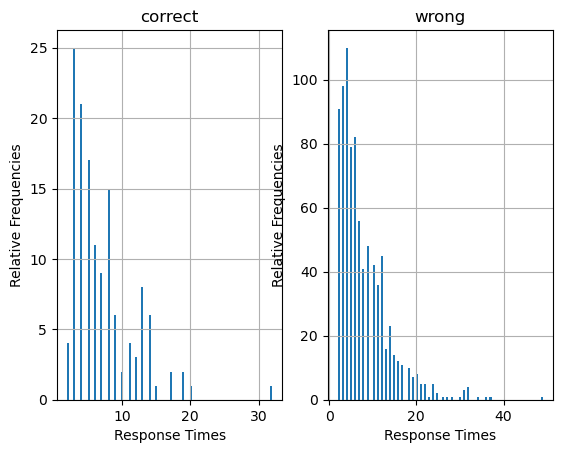

In [8]:
predictions=generate_data_t(train_model, max_steps, n=1000)
df=pd.DataFrame()
df["response"]=predictions[:,1]
df["rt"]=predictions[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

In [12]:
train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backward)

loss_function=Node({},{},nr_forward, nr_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

condition=True
while(condition):
    for t in range(max_steps):
        z = train_model.forward([z0, np.random.random()])#for now lets not train z0
        print("z:",z)

        loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

        #losses.append(loss_function.forward([y, true]))

        derivative=loss_function.back(None,-1)
        if derivative>0:
            print("----start-----")
            condition=False
        #print(derivative)
        #print(t)
        for t_back in range(t, 0-1, -1):
            #print(t_back)
            #print(train_model.memory)
            derivative=train_model.back(derivative, t_back)[0]
            print(t_back, derivative)

        if z>=1 or (z<=0):
            train_model.memory=[]
            break
    train_model.update(lr, v=True)

init params:
  sigma: 0.11063234201886463
  drift: -0.26642204383055534

z: 0.31836821664611636
0 0.0
z: 0.29924962975536085
1 0.0
0 0.0
z: 0.2638698449440907
2 -0.001369034055587504
1 -0.0008126625179029018
0 -0.0006228365531741641
z: 0.2916909191054652
3 -0.0021011202285173116
2 -0.0005753010295447997
1 -0.0003415003310647198
0 -0.0002617308961868469
z: 0.3187545038973181
4 -0.010778689544391018
3 -0.005661830659657003
2 -0.0015502477980079803
1 -0.0009202315119633416
0 -0.0007052790185433144
z: 0.2632662994883096
5 -0.004830325110973854
4 -0.0037188981978330897
3 -0.00195346305781592
2 -0.0005348714904964192
1 -0.0003175012414389975
0 -0.00024333763953662612
z: 0.2632927769366431
6 -0.003760270126703475
5 -0.0010090737342811462
4 -0.0007768923220868421
3 -0.0004080860433291126
2 -0.0001117367381855026
1 -6.632724629857387e-05
0 -5.083418092511742e-05
z: 0.3361342895469336
7 -0.002781004130600473
6 -0.0007469519110382804
5 -0.0002004455873654508
4 -0.00015432433976823574
3 -8.1063498

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
import pandas as pd
warnings.simplefilter(action='ignore', category=FutureWarning)
from collections import OrderedDict
from math import ceil

class DDM:
  """
  A class representing a Drift Diffusion Model (DDM) for simulating decision-making processes.

  Attributes:
      z0 (float): Initial starting point.
      drift (float): Drift rate, representing the average rate of accumulation of evidence.
      noise (float): Standard deviation of the noise in the accumulation process.
      nrt (int): Non-decision time, representing the time required for non-decision processes.
      betas (list): List of coefficients for each dummy coded condition, respectively.
      dependent_variable (str): Indicates which parameter is dependent on conditions ('z0' or 'drift').
      conditions (list): List of condition names.
      t_upper (float): Upper threshold for decision boundary.
      t_lower (float): Lower threshold for decision boundary.
      max_timesteps (int): Maximum number of time steps for simulation.

  Methods:
      reset(self): Resets all logged data.
      get_noise(self): Returns noise sampled from a normal distribution.
      generate_trajectory(self, plausible=None, conditions=None): Simulates a trajectory according to the DDM.
      plot_last_trajectory(self): Plots the last generated trajectory.
      plot_histogram(self, conditions=[-1,0,1], normalize="absolute", title=None): Plots histograms of response times.
      compare(self, other, normalize="joint", title=None, conditions=[-1,1], names=("model", "other"), bincount=100): Visualizes histograms of two models for comparing.
  """
  def __init__(self, z0, drift, noise, nrt, betas, dependent_variable, conditions=["RainDropDown", "Neutral", "RainDropUp"], t_upper=1, t_lower=0, max_timesteps=1000):
    """
    Initializes the DDM with given parameters.

    Parameters:
        z0 (float): Initial starting point.
        drift (float): Drift rate, representing the average rate of accumulation of evidence.
        noise (float): Standard deviation of the noise in the accumulation process.
        nrt (int): Non-decision time, representing the time required for non-decision processes.
        betas (list): List of coefficients for each dummy coded condition, respectively.
        dependent_variable (str): Indicates which parameter is dependent on conditions ('z0' or 'drift').
        conditions (list): List of condition names.
        t_upper (float): Upper threshold for decision boundary.
        t_lower (float): Lower threshold for decision boundary.
        max_timesteps (int): Maximum number of time steps for simulation.
    """
    self.z0=z0
    self.drift=drift
    self.t_upper=t_upper
    self.t_lower=t_lower
    self.noise=noise
    self.nrt=nrt
    self.dependent_variable=dependent_variable
    self.max_timesteps=max_timesteps

    conditions=np.array(conditions)
    self.dummy_encodings=conditions[conditions!="Neutral"]
    if dependent_variable in ["z0", "drift"]:
      assert len(betas)==len(conditions)-1
    self.betas=np.array(betas)

    self.log=pd.DataFrame(columns=("plausible", "rt", "response", *self.dummy_encodings))
    self.trajectory=None

  def reset(self):
    '''
    Resets all logged data
    '''
    self.log=pd.DataFrame(columns=("plausible", "rt", "response", *self.dummy_encodings))
    self.trajectory=None

  def get_noise(self):
    """
    Returns noise sampled from a normal distribution.
    """
    return np.random.normal(0,self.noise)

  def generate_trajectory(self, plausible=None, conditions=None):
    """
    Simulates a trajectory according to the DDM. Either plausible or conditions has to be provided.

    Parameters:
        plausible (int): Plausibility of the condition (1=down is correct answer, -1=up is correct answer, 0=neutral stimulus was used).
        conditions (OrderedDict): Conditions dict with keys as condition names and values as condition values. Can also be pandas DataFrame.

    Returns:
        result Tuple(int, int): Result, consisting of reaction time (rt) and correctness (response).
    """
    assert not ((plausible is None) & (conditions is None)), "Please provide either plausible or conditions or both"

    # This is not general but hard-coded for our conventions, would require a mapping param in the constrctor
    if plausible is None:
      if conditions[self.dummy_encodings[0]]==1:
        plausible=1
      elif conditions[self.dummy_encodings[1]]==1:
        plausible=-1
      else:
        plausible=-1
    elif conditions is None:
      conditions=OrderedDict({condition: 0 for condition in self.dummy_encodings})
      if plausible==-1:
        conditions[self.dummy_encodings[1]]=1
      elif plausible==1:
        conditions[self.dummy_encodings[0]]=1


    t=self.nrt
    z=self.z0
    self.last_condition=plausible
    if self.dependent_variable=="z0":
      #z0 already is the offset, so we donot need an explicit offset
      z+=np.sum(self.betas*list(conditions.values()))
    self.trajectory=[z]
    while not z>=self.t_upper and not z<self.t_lower and not t>self.max_timesteps:
      t+=1
      z+=self.get_noise()
      if self.dependent_variable=="drift":
        # self.drift already is the offset of drift(plausibility), so we do not need an additional parameter for that
        z+=self.drift+np.sum(self.betas*list(conditions.values()))
      else:
        z+=self.drift
      self.trajectory.append(z)

    if z>=self.t_upper:
      response = 1
    elif z<=self.t_lower:
      response = -1
    else:
      response = 0

    logging_dict={"plausible":plausible, "rt":t, "response":response}
    logging_dict.update(conditions)
    self.log = self.log.append(logging_dict, ignore_index=True)

    return t, response

  def plot_last_trajectory(self):
    """
    Plots the last generated trajectory.
    """
    plt.plot((0,len(self.trajectory)+self.nrt),[self.t_upper, self.t_upper])
    plt.plot((0,len(self.trajectory)+self.nrt),[self.t_lower, self.t_lower])
    plt.plot(np.r_[[0], np.arange(len(self.trajectory))+self.nrt],np.r_[self.trajectory[0], self.trajectory])
    plt.title(f"condition: {self.last_condition}")
    plt.show()

  def plot_histogram(self, conditions=[-1,0,1], normalize="absolute", title=None):
    """
    Plots histograms of response times.

    Parameters:
        conditions (list): List of conditions to include in the histogram. Same values as plausible.
        normalize (str): Normalization method ('absolute', 'marginal', or 'joint').
        title (str): Title for the plot.
    """
    if normalize=="marginal":
      # up:=unplausible, pl:=plausible
      norm=np.zeros(len(conditions))
      for i, condition in enumerate(conditions):
        norm[i]=np.array([len(self.log[self.log["plausible"]==condition])])
    elif normalize=="joint":
      norm=np.array([len(self.log)])
      if conditions:
        norm=np.tile(norm, (len(conditions),1))
    else:
      norm=np.array([1])
      if conditions:
        norm=np.tile(norm, (len(conditions),1))


    if not conditions:
      if normalize=="marginal":
        raise ValueError("yea, how's that supposed to work? No conditions -> no normalizing over the respective marginal probs...")
      fig, axs = plt.subplots(1, 2)
      axs[0].title.set_text("correct")
      axs[0].set_ylabel("Relative Frequencies")
      axs[0].set_xlabel("Response Times")
      self.log[self.log["response"]==1]["rt"].hist(ax=axs[0], bins=100)
      #df_c.hist(ax=axs[0], label=f'correct', alpha=0.7, weights=(1/norm).repeat(len(df_pc)))
      axs[1].set_ylabel("Relative Frequencies")
      axs[1].set_xlabel("Response Times")
      self.log[self.log["response"]==-1]["rt"].hist(ax=axs[1], bins=100)
      axs[1].title.set_text("wrong")
    else:
      fig, axs = plt.subplots(1, 2)

      for i, condition in enumerate(conditions):

        df_pc=self.log[(self.log["response"]==1) & (self.log["plausible"]==condition)]["rt"]
        df_pc.hist(ax=axs[0], label=f'plausibility: {condition}', alpha=0.7, weights=(1/norm[i]).repeat(len(df_pc)))
        axs[0].title.set_text("correct")

        if normalize=="joint":
          axs[0].set_ylabel("Relative Frequencies")
        elif normalize=="marginal":
          axs[0].set_ylabel("Conditional relative Frequencies")
        else:
          axs[0].set_ylabel("Absolute Frequencies")

        axs[0].set_xlabel("Response Times")

        df_pw=self.log[(self.log["response"]==-1) & (self.log["plausible"]==condition)]["rt"]
        df_pw.hist(ax=axs[1], label=f'plausibility: {condition}', alpha=0.7, weights=(1/norm[i]).repeat(len(df_pw)))
        axs[1].title.set_text("wrong")

      plt.legend()
    if title:
      fig.suptitle(title)
    plt.show()


  def compare(self, other, normalize="joint", title=None, conditions=[-1,1], names=("model", "other"), bincount=100):
    """
    Compares histograms between two models.

    Parameters:
        other (DataFrame): DataFrame representing the data from the other model/distribution.
        normalize (str): Normalization method ('joint' or 'absolute'). No normalization by marginal distributions.
        title (str): Title for the plot.
        conditions (list): List of conditions to compare.
        names (tuple): Names of the models being compared.
        bincount (int): Number of bins for the histograms.
    """
    if normalize=="joint": # comparing after normalizing with marginal prob should not be done, the marginal distributions have to be learned as well
      norm_model=np.array([len(self.log)])
      norm_other=np.array([len(other)])
    else:
      norm_other=norm_model=np.array([1])

    fig, axs = plt.subplots(len(conditions), 2, figsize=(18,18))

    min_self=self.log.groupby(["response", "plausible"]).min()
    max_self=self.log.groupby(["response", "plausible"]).max()

    min_other=other.groupby(["response", "plausible"]).min()
    max_other=other.groupby(["response", "plausible"]).max()

    mins=min_self.join(min_other, lsuffix='_self', rsuffix='_other').min(axis="columns").reset_index()
    max_=max_self.join(max_other, lsuffix='_self', rsuffix='_other').max(axis="columns").reset_index()

    for i, condition in enumerate(conditions):
      try:
        min_uc=mins[(mins["response"]==1)&(mins["plausible"]==condition)].iloc[0,2]
      except IndexError:
        min_uc=0
      try:
        max_uc=max_[(max_["response"]==1)&(max_["plausible"]==condition)].iloc[0,2]
      except:
        max_uc=self.max_timesteps
      range_uc=max_uc-min_uc
      step=ceil(range_uc/bincount)
      max_uc+=step
      bins_uc=np.arange(min_uc, max_uc, step)

      df_uc=self.log[(self.log["response"]==1) & (self.log["plausible"]==condition)]["rt"]
      df_uc.hist(ax=axs[i,0], label=names[0], alpha=0.7, weights=(1/norm_model).repeat(len(df_uc)),bins=bins_uc)

      df_uc_other=other[(other["response"]==1) & (other["plausible"]==condition)]["rt"]
      df_uc_other.hist(ax=axs[i,0], label=names[1], alpha=0.7, weights=(1/norm_other).repeat(len(df_uc_other)),bins=bins_uc)
      axs[i,0].title.set_text(f"correct, plausibility={condition}")

      if i==len(conditions)-1:

        if normalize=="joint":
          axs[i,0].set_ylabel("Relative Frequencies")
        else:
          axs[i,0].set_ylabel("Absolute Frequencies")

      try:
        min_uw=mins[(mins["response"]==-1)&(mins["plausible"]==condition)].iloc[0,2]
      except IndexError:
        min_uw=0
      try:
        max_uw=max_[(max_["response"]==-1)&(max_["plausible"]==condition)].iloc[0,2]
      except IndexError:
        max_uw=self.max_timesteps

      range_uw=max_uw-min_uw
      step=ceil(range_uw/bincount)
      max_uw+=step
      bins_uw=np.arange(min_uw, max_uw, step)

      df_uw=self.log[(self.log["response"]==-1) & (self.log["plausible"]==condition)]["rt"]
      df_uw.hist(ax=axs[i,1], label=names[0], alpha=0.7, weights=(1/norm_model).repeat(len(df_uw)),bins=bins_uw)

      df_uw_other=other[(other["response"]==-1) & (other["plausible"]==condition)]["rt"]
      df_uw_other.hist(ax=axs[i,1], label=names[1], alpha=0.7, weights=(1/norm_other).repeat(len(df_uw_other)),bins=bins_uw)
      axs[i,1].title.set_text(f"wrong, plausibility={condition}")

      axs[i,1].legend()
    if title:
      fig.suptitle(title)
    plt.show()


In [2]:
!pip install cm-course-uos --upgrade

  Using cached cm_course_uos-1.5.15-py3-none-any.whl.metadata (902 bytes)
Using cached cm_course_uos-1.5.15-py3-none-any.whl (17 kB)


In [4]:
!pip install git+https://github.com/lnccbrown/HSSM.git

  Cloning https://github.com/lnccbrown/HSSM.git to c:\users\admin\appdata\local\temp\pip-req-build-cm0d4fkp
  Resolved https://github.com/lnccbrown/HSSM.git to commit 19f786d9abeca00aa6af6d0740598bebb80ae6d3
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
INFO: pip is looking at multiple versions of hssm to determine which version is compatible with other requirements. This could take a while.


  Running command git clone --filter=blob:none --quiet https://github.com/lnccbrown/HSSM.git 'C:\Users\admin\AppData\Local\Temp\pip-req-build-cm0d4fkp'
ERROR: Ignored the following versions that require a different python version: 0.18.0 Requires-Python >=3.10
ERROR: Could not find a version that satisfies the requirement arviz<0.19.0,>=0.18.0 (from hssm) (from versions: 0.0.1, 0.1.0, 0.2.0, 0.2.1, 0.3.0, 0.3.1, 0.3.2, 0.3.3, 0.4.0, 0.4.1, 0.5.1, 0.6.0, 0.6.1, 0.7.0, 0.8.0, 0.8.1, 0.8.2, 0.8.3, 0.9.0, 0.10.0, 0.11.0, 0.11.1, 0.11.2, 0.11.3, 0.11.4, 0.12.0, 0.12.1, 0.13.0rc1, 0.13.0, 0.14.0, 0.15.0, 0.15.1, 0.16.0, 0.16.1, 0.17.0, 0.17.1)
ERROR: No matching distribution found for arviz<0.19.0,>=0.18.0


In [1]:


from cm_course_uos import problemset4

coherence_dataset = problemset4.get_dot_data_set()


ModuleNotFoundError: No module named 'hssm'

# Optimize z=1 at mean(z_t-1, z_t), Noiseless
So far we can find the correct drift, but oscillate around the correct value (feels like reaching correct value, still go one step further due to loss minimum not being zero and then get elephanted several steps back)

todos:
- remove the bias of the loss and bias the gradients instead, by assuming we get the correct value at the t with z=1
- make elephant less aggressive
- finally do the CE thingnoise_replacement

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless

import pandas as pd
from tqdm import tqdm

In [2]:
class Node:
    def __init__(self, free_params, constants, operation, derivative):
        self.free_params_dict=dict(zip(free_params,np.arange(len(free_params))))
        self.free_params=np.array(list(free_params.values()))
        self.constants=constants
        self.memory=[]
        self.operation=operation
        self.derivative=derivative
        self.gradients=[]
        
    def forward(self,x):
        self.memory.append(x)
        return self.operation(self.constants, self.free_params, x)
    
    def back(self, df, t=None, v=False):
        """
        params:
            df (float): gradient of the next operation aka derivative of all that happens after this node
        """
        x=self.memory[t]
        #x=self.memory.pop()
        gradients=self.derivative(self.constants, self.free_params, x, df)
        self.gradients.append(gradients[:len(self.free_params)])
        if v==True:
            print(f"gradient at {t}: {self.gradients[-1]}")
            print(f"for inputs x",x)
        return gradients
    
    def update(self, lr, v=False):
        """
        terrible efficiency, todo: use dict only for mapping index to name and work on an array
        """
        #for key in np.arange(len(self.free_params)):
        #print(self.gradients)
        self.free_params-=lr*np.sum(self.gradients, axis=0)
        if v:
            print("updates:",-lr*np.sum(self.gradients, axis=0))
            print("individual updates: -",self.gradients)
        self.gradients=[]
    

In [ ]:
f(z2) = z2+drift+std*noise
z2(z1) = z1+drift+std*noise
df/dz1 = df/z2 (z2) * dz2/dz1

In [3]:
def ddm_forward(constants, free_params, x):
    """
    expects x[0]=z and x[1]=noise
    """
    #print(f"{x[0]}+{x[1]}*{free_params[0]}+{free_params[1]}")
    return x[0]+x[1]*free_params[0]+free_params[1]

def ddm_backward(constants, free_params, x, df):
    """
    should give deriatives wrt z, drift and noise, nrt has to be somehow included in the loss function
    df (float): derivative of previous functions
    """
    #print(df, x)
    #return df*1, df*1, df*x[1] so far no z0
    return df*x[1], df*1, df*1#here

def l2_forward(_, __, x):
    """
    x[0]=y, x[1]=true (convention: inputs first, constants last)
    """
    return 1/2*(x[0]-x[1])**2

def l2_backward(_, __, x, ___):
    """
    gotta give gradient wrt input
    """
    return x[0]-x[1]

def mean_forward(_, __, x):
    return (x[0]+x[1])/2

def mean_backward(_, __, x, ___):
    """
    f = 1/2*x0 + 1/2*x1
    df/dx0 = 1/2
    """
    return 

def mean_l2_forward(constants, __, x):
    return 1/2*(constants - (1/2 * x[0] + 1/2 * x[1]))**2

def mean_l2_backward(constants, __, x, ___):
    df = -1/2*constants + 1/4*x[0] + 1/4*x[1]
    return df, df
"""
f = 1/2(1 - (1/2 x0 + 1/2 x1))**2
f = 1/2(1 - 1/2x0 - 1/2x1)**2

g(h) = 1/2h**2
h(x0, x1) = 1 - 1/2x0 - 1/2x1

df/dx = dh/dx (x) * dg/dx (h)

dh/dx0 = - 1/2

dg/dx = h

df/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)
        = - 1/2 - 1/4 x0 - 1/4 x1

df/dx0 = 
"""

'\nf = 1/2(1 - (1/2 x0 + 1/2 x1))**2\nf = 1/2(1 - 1/2x0 - 1/2x1)**2\n\ng(h) = 1/2h**2\nh(x0, x1) = 1 - 1/2x0 - 1/2x1\n\ndf/dx = dh/dx (x) * dg/dx (h)\n\ndh/dx0 = - 1/2\n\ndg/dx = h\n\ndf/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)\n        = - 1/2 - 1/4 x0 - 1/4 x1\n\ndf/dx0 = \n'

      response     rt
0          1.0   76.0
1          1.0   39.0
2          1.0   49.0
3          1.0   33.0
4          1.0   36.0
...        ...    ...
9995       1.0   19.0
9996       1.0   77.0
9997       1.0  137.0
9998       1.0   13.0
9999       1.0   41.0

[10000 rows x 2 columns]


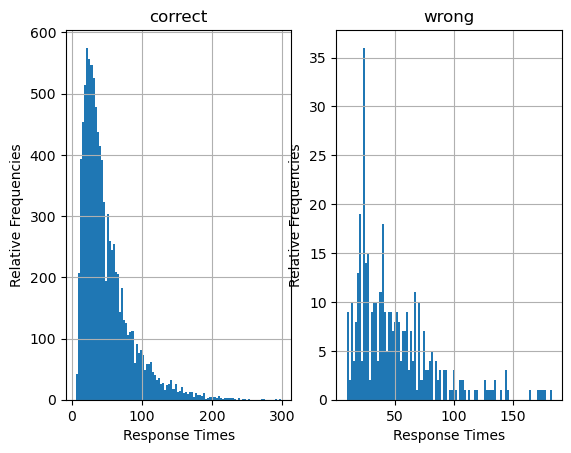

0.96


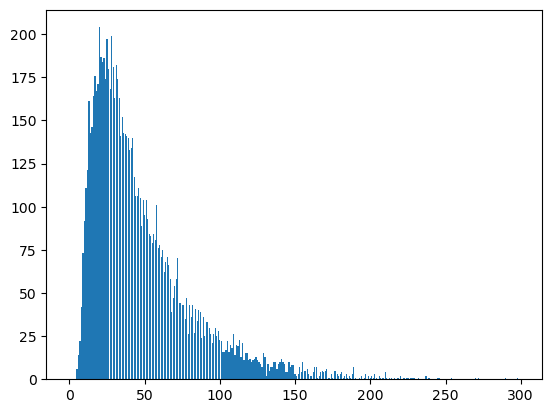

beware the elefant cause it punishes good stuff too hard


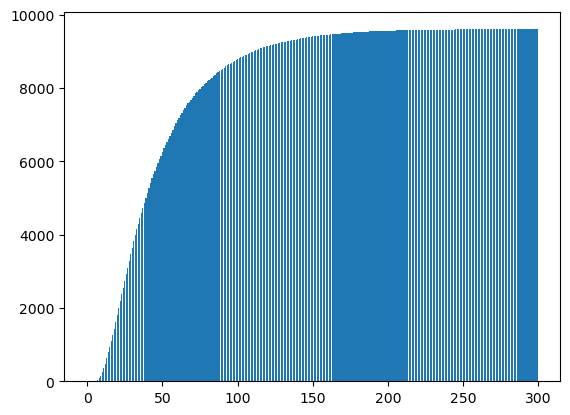

original params:
  sigma: 0.2
  drift: 0.01

init params:
  sigma: 0.23625192336608725
  drift: 0.1784346933558888



 11%|███████▊                                                                 | 10738/100000 [00:01<00:13, 6498.24it/s]

loss: 0.01690168394278625
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.23625192336608725
  drift: 0.023845195593840657



 21%|███████████████▌                                                         | 21270/100000 [00:03<00:12, 6213.89it/s]

loss: 0.0009211151857174201
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.23625192336608725
  drift: 0.023855460552782596



 31%|██████████████████████▌                                                  | 30876/100000 [00:05<00:11, 5933.23it/s]

... (11 outputs left out)

 91%|██████████████████████████████████████████████████████████████████▋      | 91275/100000 [00:15<00:01, 6648.93it/s]

loss: 0.0009211161373803272
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.23625192336608725
  drift: 0.02374121234363576



100%|████████████████████████████████████████████████████████████████████████| 100000/100000 [00:17<00:00, 5871.02it/s]


loss: 0.0009211161470326763
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.23625192336608725
  drift: 0.023748179945466425

wasted_runs 0


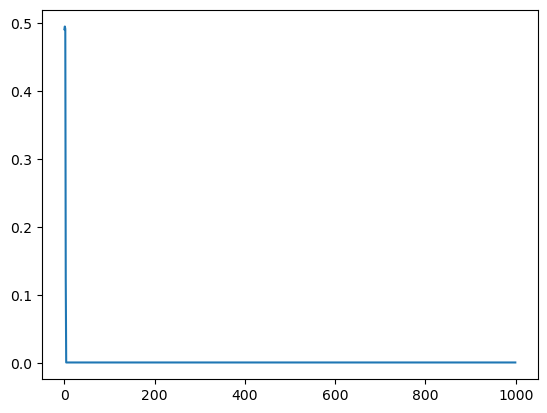

In [4]:
# so i guess the gradient for z is not 1




# 1st: there is gotta be a bug or a bias I did not understand at all: drift always becomes negative! 
# -> bug found: noise was not zero centered

# !!forgot to use cumulative dist!!

# 2nd: try using the normalized diff p_t,true-p_t,false
# 3rd: try our using ce of cheated distribution over batch
# misc: show ce

# generate dataset over t
z0=0.5
sigma=0.2
drift=0.01
max_steps=300
epochs=100000
lr=0.0001
n_data=10000

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
#print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

# (response, rt)
data_dist=np.zeros((2, max_steps))
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))

data_dist[0,:]=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
size0=data_dist[0].sum()/n_data
print(size0)


mode=np.argmax(data_dist[0,:])
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()
#fuck efficient coding for now
for i in range(1,len(data_dist[0])):
    data_dist[0,i]=np.sum(data_dist[0,i-1:i+1])
    
print("beware the elefant cause it punishes good stuff too hard")
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()

data_dist[0,:]/=data_dist[0,mode]

#plt.bar(np.arange(len(data_dist[0])),data_dist[0])
#plt.show()



data_dist[1,:]=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]
size1=data_dist[1].sum()/n_data

mode=np.argmax(data_dist[1,:])
#fuck efficient coding for now
for i in range(1,len(data_dist[1])):
    data_dist[1,i]=np.sum(data_dist[1,i-1:i+1])

data_dist[1,:]/=data_dist[1,mode]





print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backward)

loss_function_f=mean_l2_forward#
loss_function_b=mean_l2_backward#Node({},{},l2_forward, l2_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]

too_fast=0
too_slow=0
good_runs=0

for epoch in tqdm(range(epochs)):
    z=z0
    z_old=z0
    for t in range(max_steps):
        z = train_model.forward([z, 0])#np.random.random()-0.5])#for now lets not train z0

        #loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

        #losses.append(loss_function.forward([y, true]))
        
        #derivative=loss_function.back(None,-1)
        #print(derivative)
        #print(t)
        
        if z>=1 or (z<=0):
            if t==0:
                too_fast+=1
                break
            if z>=1:
                target = np.mean(data_dist[0,t-1:t+1])
                size=size0
            else:
                target = 1- np.mean(data_dist[1,t-1:t+1])
                size=size1
                
            losses.append(loss_function_f(target, None, (z_old, z)))
            
            #train_model.memory=[]
            derivative1, derivative2 = loss_function_b(target, None, (z_old, z), None)
            derivative1*=size
            derivative2*=size
            
            for t_back in range(t, 0-1, -1):
                
                derivative1=train_model.back(derivative1, t_back)[-1]#gradient for downstream/inputs will be last
                
                if t_back<t:
                    derivative2=train_model.back(derivative2, t_back)[-1]
                   
            good_runs+=1
            break
                
        z_old=z
        
    if t==max_steps-1:
        too_slow+=1
        
    train_model.update(lr)
    
    if not (epoch+1)%(epochs/10):
        print("loss:", np.mean(losses[-int(epochs/10):]))
        print("n too fast:", too_fast)
        print("n too slow:", too_slow)
        # self-check if insane
        print("n good_runs:", good_runs)
        too_fast=0
        too_slow=0
        good_runs=0
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

wasted_runs=epochs-len(losses)
if (len(losses)%100):
    losses = losses[:-(len(losses)%100)]
losses=np.array(losses)
print("wasted_runs",wasted_runs)
plt.plot(np.arange(int(len(losses)/100)), np.mean(np.split(losses, int(len(losses)/100)), axis=1))
plt.show()

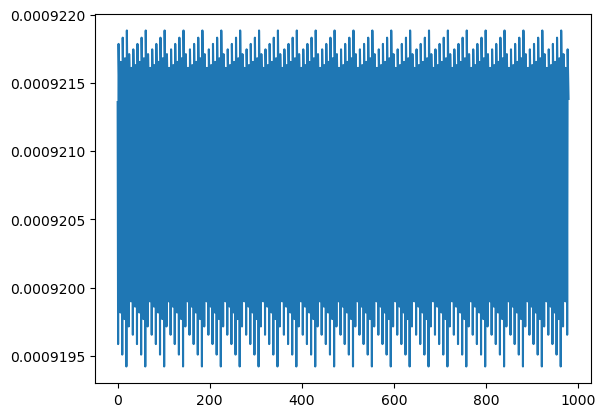

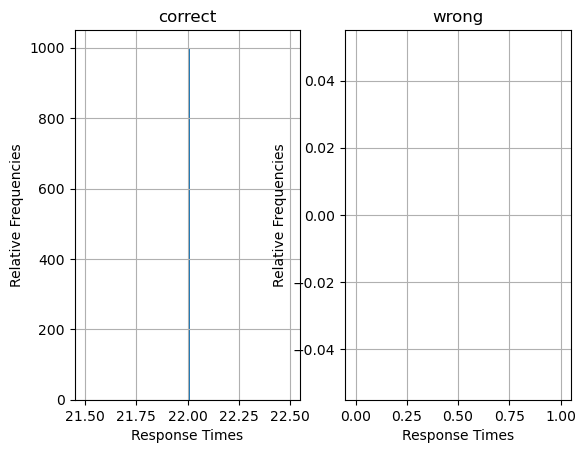

0.0
20
1.0


In [5]:
losses2=losses[2000:]
plt.plot(np.arange(int(len(losses2)/100)), np.mean(np.split(losses2, int(len(losses2)/100)), axis=1))
plt.show()

plot_dist_noiseless(train_model, max_steps)
print(data_dist[0,2])
print((data_dist[0]==1.0).argmax())
print(data_dist[0,(data_dist[0]==1.0).argmax()])

In [2]:
(8.8*590)/60

86.53333333333333

# Optimize z=1 at mean(z_t-1, z_t), Noiseless, repair loss, lr-annealing
Now loss function only depends on actual last step and still works just as good as before, oscillation seems to stem from lr, annealing solves oscillation but we do have a bias (probably because we are a tiny bit smaller than 1 at t, just weird that this behaviour does not get elephanted

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless

import pandas as pd
from tqdm import tqdm

In [2]:
class Node:
    def __init__(self, free_params, constants, operation, derivative):
        self.free_params_dict=dict(zip(free_params,np.arange(len(free_params))))
        self.free_params=np.array(list(free_params.values()))
        self.constants=constants
        self.memory=[]
        self.operation=operation
        self.derivative=derivative
        self.gradients=[]
        
    def forward(self,x):
        self.memory.append(x)
        return self.operation(self.constants, self.free_params, x)
    
    def back(self, df, t=None, v=False):
        """
        params:
            df (float): gradient of the next operation aka derivative of all that happens after this node
        """
        x=self.memory[t]
        #x=self.memory.pop()
        gradients=self.derivative(self.constants, self.free_params, x, df)
        self.gradients.append(gradients[:len(self.free_params)])
        if v==True:
            print(f"gradient at {t}: {self.gradients[-1]}")
            print(f"for inputs x",x)
        return gradients
    
    def update(self, lr, v=False):
        """
        terrible efficiency, todo: use dict only for mapping index to name and work on an array
        """
        #for key in np.arange(len(self.free_params)):
        #print(self.gradients)
        self.free_params-=lr*np.sum(self.gradients, axis=0)
        if v:
            print("updates:",-lr*np.sum(self.gradients, axis=0))
            print("individual updates: -",self.gradients)
        self.gradients=[]
    

In [4]:
def ddm_forward(constants, free_params, x):
    """
    expects x[0]=z and x[1]=noise
    """
    #print(f"{x[0]}+{x[1]}*{free_params[0]}+{free_params[1]}")
    return x[0]+x[1]*free_params[0]+free_params[1]

def ddm_backward(constants, free_params, x, df):
    """
    should give deriatives wrt z, drift and noise, nrt has to be somehow included in the loss function
    df (float): derivative of previous functions
    """
    #print(df, x)
    #return df*1, df*1, df*x[1] so far no z0
    return df*x[1], df*1, df*1#here

def l2_forward(constants, __, x):
    """
    x[0]=y, x[1]=true (convention: inputs first, constants last)
    """
    return 1/2*(x-constants)**2

def l2_backward(constants, __, x, ___):
    """
    gotta give gradient wrt input
    """
    return x-constants

def mean_l2_forward(constants, __, x):
    return 1/2*(constants - (1/2 * x[0] + 1/2 * x[1]))**2

def mean_l2_backward(constants, __, x, ___):
    df = -1/2*constants + 1/4*x[0] + 1/4*x[1]
    return df, df
"""
f = 1/2(1 - (1/2 x0 + 1/2 x1))**2
f = 1/2(1 - 1/2x0 - 1/2x1)**2

g(h) = 1/2h**2
h(x0, x1) = 1 - 1/2x0 - 1/2x1

df/dx = dh/dx (x) * dg/dx (h)

dh/dx0 = - 1/2

dg/dx = h

df/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)
        = - 1/2 - 1/4 x0 - 1/4 x1

df/dx0 = 
"""

'\nf = 1/2(1 - (1/2 x0 + 1/2 x1))**2\nf = 1/2(1 - 1/2x0 - 1/2x1)**2\n\ng(h) = 1/2h**2\nh(x0, x1) = 1 - 1/2x0 - 1/2x1\n\ndf/dx = dh/dx (x) * dg/dx (h)\n\ndh/dx0 = - 1/2\n\ndg/dx = h\n\ndf/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)\n        = - 1/2 - 1/4 x0 - 1/4 x1\n\ndf/dx0 = \n'

      response    rt
0         -1.0  61.0
1         -1.0  48.0
2         -1.0  79.0
3         -1.0  81.0
4         -1.0  31.0
...        ...   ...
9995      -1.0  20.0
9996      -1.0  65.0
9997      -1.0  34.0
9998      -1.0  83.0
9999      -1.0  73.0

[10000 rows x 2 columns]


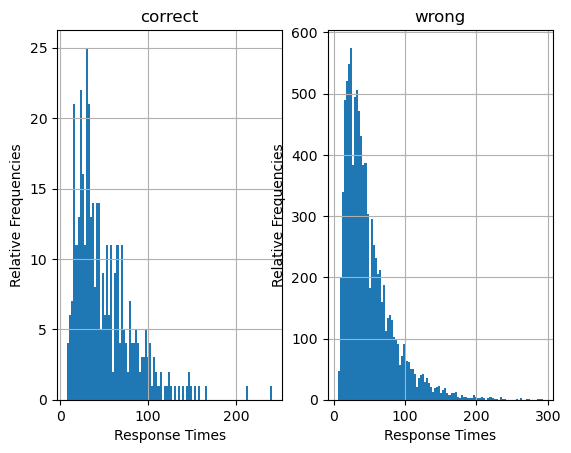

0.0386


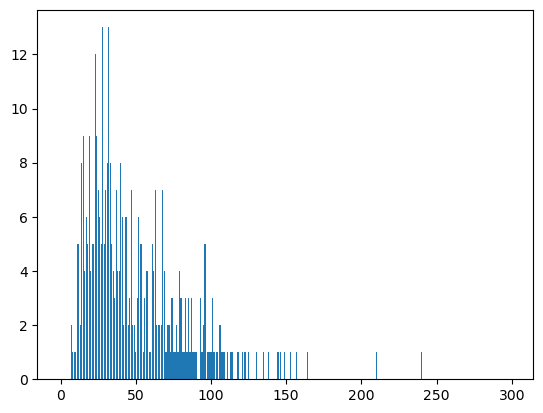

beware the elefant cause it punishes good stuff too hard


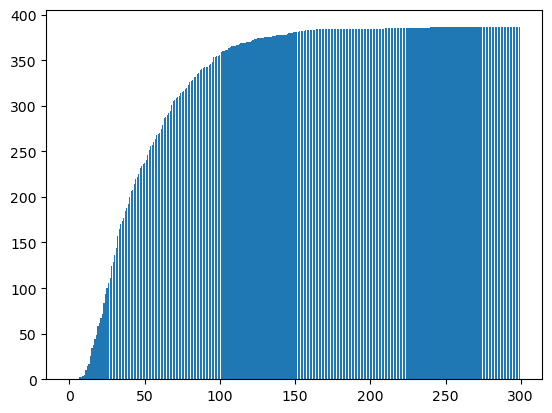

original params:
  sigma: 0.2
  drift: -0.01

init params:
  sigma: 0.41815358261485136
  drift: 0.1



 12%|████████▍                                                                | 11568/100000 [00:01<00:13, 6326.17it/s]

loss: 0.005742588499486598
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.41815358261485136
  drift: 0.017241379310520333



 21%|███████████████▎                                                         | 21045/100000 [00:03<00:11, 6781.50it/s]

loss: 1.458176565454788e-26
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.41815358261485136
  drift: 0.017241379310344862



 32%|███████████████████████                                                  | 31608/100000 [00:05<00:11, 6203.08it/s]

... (11 outputs left out)

 91%|██████████████████████████████████████████████████████████████████▊      | 91470/100000 [00:13<00:01, 8396.25it/s]

loss: 3.944304526105059e-31
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.41815358261485136
  drift: 0.017241379310344862



100%|████████████████████████████████████████████████████████████████████████| 100000/100000 [00:14<00:00, 6774.46it/s]


loss: 3.944304526105059e-31
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.41815358261485136
  drift: 0.017241379310344862

wasted_runs 0


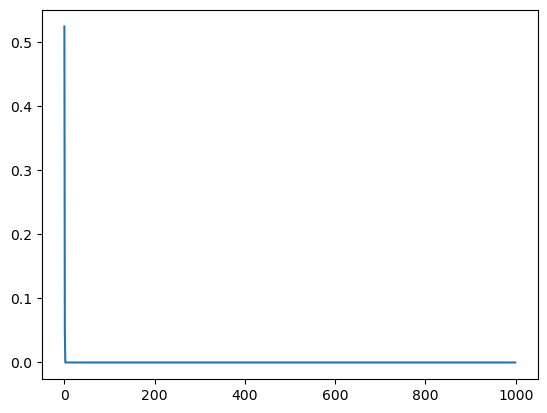

In [12]:

z0=0.5
sigma=0.2
drift=-0.01
max_steps=300
epochs=100000
lr=0.002
n_data=10000

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
#print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

# (response, rt)
data_dist=np.zeros((2, max_steps))
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))

data_dist[0,:]=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
size0=data_dist[0].sum()/n_data
print(size0)


mode=np.argmax(data_dist[0,:])
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()
#fuck efficient coding for now
for i in range(1,len(data_dist[0])):
    data_dist[0,i]=np.sum(data_dist[0,i-1:i+1])
    
print("beware the elefant cause it punishes good stuff too hard")
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()

data_dist[0,:]/=data_dist[0,mode]

#plt.bar(np.arange(len(data_dist[0])),data_dist[0])
#plt.show()



data_dist[1,:]=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]
size1=data_dist[1].sum()/n_data

mode=np.argmax(data_dist[1,:])
#fuck efficient coding for now
for i in range(1,len(data_dist[1])):
    data_dist[1,i]=np.sum(data_dist[1,i-1:i+1])

data_dist[1,:]/=data_dist[1,mode]





print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

drift_train_init=0.1#np.random.random()-0.5
train_model=Node({"sigma": np.random.random(), "drift": drift_train_init}, dict(), ddm_forward, ddm_backward)

loss_function_f=l2_forward#mean_l2_forward#
loss_function_b=l2_backward#mean_l2_backward#Node({},{},l2_forward, l2_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]

too_fast=0
too_slow=0
good_runs=0

for epoch in tqdm(range(epochs)):
    z=z0
    z_old=z0
    for t in range(max_steps):
        z = train_model.forward([z, 0])#np.random.random()-0.5])#for now lets not train z0

        #loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

        #losses.append(loss_function.forward([y, true]))
        
        #derivative=loss_function.back(None,-1)
        #print(derivative)
        #print(t)
        
        if z>=1 or (z<=0):
            if t==0:
                too_fast+=1
                break
            if z>=1:
                #target = np.mean(data_dist[0,t-1:t+1])#not sure why im taking the mean here
                target=data_dist[0,t]
                size=size0
            else:
                #target = 1- np.mean(data_dist[1,t-1:t+1])
                target=1-data_dist[1,t]
                size=size1
                
            losses.append(loss_function_f(target, None, z))
            
            #train_model.memory=[]
            derivative1 = loss_function_b(target, None, z, None)
            derivative1*=size
            #derivative2*=size
            
            for t_back in range(t, 0-1, -1):
                
                derivative1=train_model.back(derivative1, t_back)[-1]#gradient for downstream/inputs will be last
                
                '''if t_back<t:
                    derivative2=train_model.back(derivative2, t_back)[-1]'''
                   
            good_runs+=1
            break
                
        z_old=z
        
    if t==max_steps-1:
        too_slow+=1
        
    train_model.update(lr)
    
    if not (epoch+1)%(epochs/10):
        lr=lr*0.7
        print("loss:", np.mean(losses[-int(epochs/10):]))
        print("n too fast:", too_fast)
        print("n too slow:", too_slow)
        # self-check if insane
        print("n good_runs:", good_runs)
        too_fast=0
        too_slow=0
        good_runs=0
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

wasted_runs=epochs-len(losses)
if (len(losses)%100):
    losses = losses[:-(len(losses)%100)]
losses=np.array(losses)
print("wasted_runs",wasted_runs)
plt.plot(np.arange(int(len(losses)/100)), np.mean(np.split(losses, int(len(losses)/100)), axis=1))
plt.show()

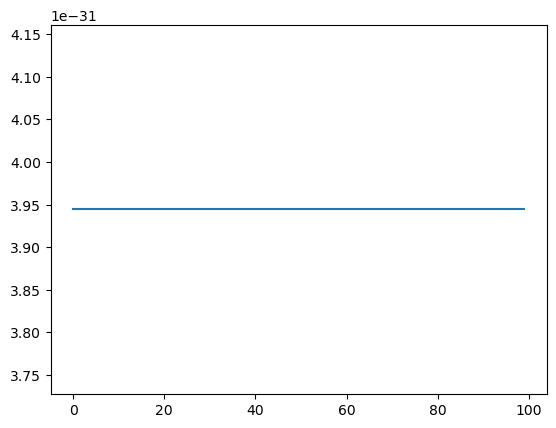

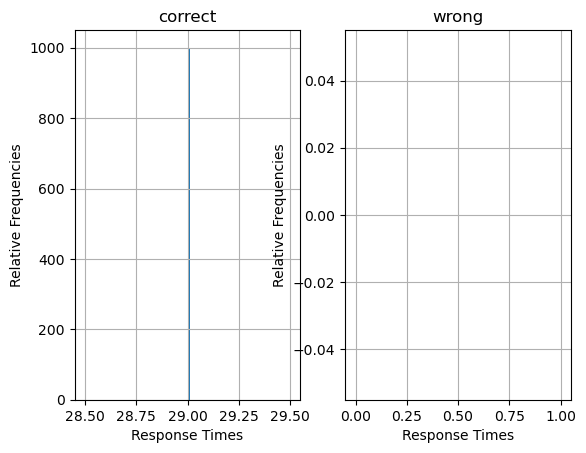

0.0
23
1.0


In [13]:
losses2=losses[90000:]
plt.plot(np.arange(int(len(losses2)/100)), np.mean(np.split(losses2, int(len(losses2)/100)), axis=1))
plt.show()

plot_dist_noiseless(train_model, max_steps)
print(data_dist[0,2])
print((data_dist[1]==1.0).argmax())
print(data_dist[1,(data_dist[1]==1.0).argmax()])

# Succesfully and Robustly predicting the Mode
last step: fix memory buffer not reseting (unsafe!!)

now the model seems to be able to learn the mode almost perfectly (noise goes to zero)

warning: noise is not gaussian cause I'm stupid (does it matter though? I guess its not real DDM with uniform noise, but so what)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless

import pandas as pd
from tqdm import tqdm

In [3]:
class Node:
    def __init__(self, free_params, constants, operation, derivative):
        self.free_params_dict=dict(zip(free_params,np.arange(len(free_params))))
        self.free_params=np.array(list(free_params.values()))
        self.constants=constants
        self.memory=[]
        self.operation=operation
        self.derivative=derivative
        self.gradients=[]
        
    def forward(self,x, v=False):
        self.memory.append(x)
        return self.operation(self.constants, self.free_params, x, v=v)
    
    def back(self, df, t=None, v=False):
        """
        params:
            df (float): gradient of the next operation aka derivative of all that happens after this node
        """
        x=self.memory[t]
        #x=self.memory.pop()
        gradients=self.derivative(self.constants, self.free_params, x, df)
        self.gradients.append(gradients[:len(self.free_params)])
        if v==True:
            print(f"gradient at {t}: {self.gradients[-1]}")
            print(f"for inputs x",x)
        return gradients
    
    def update(self, lr, v=False):
        """
        terrible efficiency, todo: use dict only for mapping index to name and work on an array
        """
        #for key in np.arange(len(self.free_params)):
        #print(self.gradients)
        if np.isnan(self.gradients).any():
            v=True
        self.free_params-=lr*np.sum(self.gradients, axis=0)
        if v:
            print("updates:",-lr*np.sum(self.gradients, axis=0))
            print("individual updates: ",-self.gradients)
            raise Exception
        self.gradients=[]
        self.memory=[]
    

In [4]:
def ddm_forward(constants, free_params, x, v=False):
    """
    expects x[0]=z and x[1]=noise
    """
    if v:
        print(f"{x[0]}+{x[1]}*{free_params[0]}+{free_params[1]}")
    return x[0]+x[1]*free_params[0]+free_params[1]

def ddm_backward(constants, free_params, x, df):
    """
    should give deriatives wrt noise, drift and z, nrt has to be somehow included in the loss function
    df (float): derivative of previous functions
    """
    #print(df, x)
    #return df*1, df*1, df*x[1] so far no z0
    return df*x[1], df*1, df*1#here

def l2_forward(constants, __, x):
    """
    x[0]=y, x[1]=true (convention: inputs first, constants last)
    """
    return 1/2*(x-constants)**2

def l2_backward(constants, __, x, ___):
    """
    gotta give gradient wrt input
    """
    return x-constants

def mean_l2_forward(constants, __, x):
    return 1/2*(constants - (1/2 * x[0] + 1/2 * x[1]))**2

def mean_l2_backward(constants, __, x, ___):
    df = -1/2*constants + 1/4*x[0] + 1/4*x[1]
    return df, df
"""
f = 1/2(1 - (1/2 x0 + 1/2 x1))**2
f = 1/2(1 - 1/2x0 - 1/2x1)**2

g(h) = 1/2h**2
h(x0, x1) = 1 - 1/2x0 - 1/2x1

df/dx = dh/dx (x) * dg/dx (h)

dh/dx0 = - 1/2

dg/dx = h

df/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)
        = - 1/2 - 1/4 x0 - 1/4 x1

df/dx0 = 
"""

'\nf = 1/2(1 - (1/2 x0 + 1/2 x1))**2\nf = 1/2(1 - 1/2x0 - 1/2x1)**2\n\ng(h) = 1/2h**2\nh(x0, x1) = 1 - 1/2x0 - 1/2x1\n\ndf/dx = dh/dx (x) * dg/dx (h)\n\ndh/dx0 = - 1/2\n\ndg/dx = h\n\ndf/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)\n        = - 1/2 - 1/4 x0 - 1/4 x1\n\ndf/dx0 = \n'

In [9]:
0.75**15

0.013363461010158062

      response     rt
0          1.0  186.0
1          0.0    0.0
2          1.0   88.0
3          1.0   90.0
4          1.0  200.0
...        ...    ...
9995       0.0    0.0
9996       1.0   52.0
9997       1.0  274.0
9998       1.0  237.0
9999       0.0    0.0

[10000 rows x 2 columns]


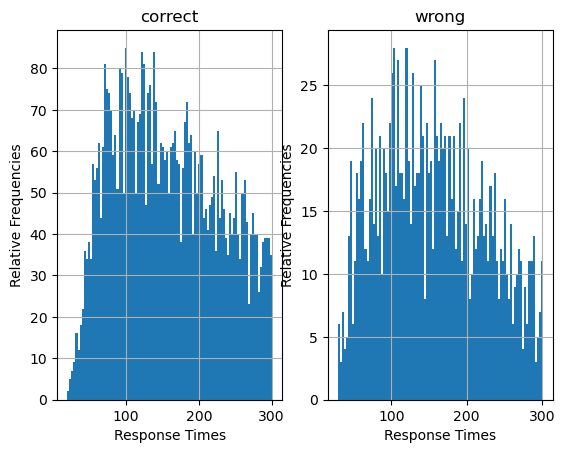

Exception: 

In [8]:

z0=0.5
sigma=0.1
drift=0.001
max_steps=300
epochs=10000000#-00
lr=0.0001
n_data=10000

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
#print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

raise Exception

# (response, rt)
data_dist=np.zeros((2, max_steps))
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))

data_dist[0,:]=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
size0=data_dist[0].sum()/n_data
print(size0)


mode=np.argmax(data_dist[0,:])
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()
#fuck efficient coding for now
for i in range(1,len(data_dist[0])):
    data_dist[0,i]=np.sum(data_dist[0,i-1:i+1])
    
print("beware the elefant cause it punishes good stuff too hard")
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()

data_dist[0,:]/=data_dist[0,mode]

#plt.bar(np.arange(len(data_dist[0])),data_dist[0])
#plt.show()



data_dist[1,:]=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]
size1=data_dist[1].sum()/n_data

mode=np.argmax(data_dist[1,:])
#fuck efficient coding for now
for i in range(1,len(data_dist[1])):
    data_dist[1,i]=np.sum(data_dist[1,i-1:i+1])

gentleness=100
if not np.max(data_dist[1,:]):
    data_dist[1,:]=0#1/gentleness#1#0#np.max(data_dist[0,:])
    size1=1/gentleness
else:
    data_dist[1,:]/=data_dist[1,mode]





print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backward)

loss_function_f=l2_forward#mean_l2_forward#
loss_function_b=l2_backward#mean_l2_backward#Node({},{},l2_forward, l2_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]

too_fast=0
too_slow=0
good_runs=0

for epoch in tqdm(range(epochs)):
    z=z0
    z_old=z0
    for t in range(max_steps):
        z = train_model.forward([z, np.random.random()-0.5])#np.random.random()-0.5])#for now lets not train z0

        #loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

        #losses.append(loss_function.forward([y, true]))
        
        #derivative=loss_function.back(None,-1)
        #print(derivative)
        #print(t)
        
        if z>=1 or (z<=0) or (t==max_steps-1):
            if z>=1:
                #target = np.mean(data_dist[0,t-1:t+1])#not sure why im taking the mean here
                target=data_dist[0,t]
                size=size0
            else:
                #target = 1- np.mean(data_dist[1,t-1:t+1])
                target=1-data_dist[1,t]
                size=size1
                
            losses.append(loss_function_f(target, None, z))
            
            #train_model.memory=[]
            derivative1 = loss_function_b(target, None, z, None)
            derivative1*=size
            #derivative2*=size
            
            for t_back in range(t, 0-1, -1):
                
                derivative1=train_model.back(derivative1, t_back)[-1]#gradient for downstream/inputs will be last
                
                '''if t_back<t:
                    derivative2=train_model.back(derivative2, t_back)[-1]'''
                   
            if t==0:
                too_fast+=1
            else:
                good_runs+=1
            break
                
        z_old=z
        
    if t==max_steps-1:
        too_slow+=1
        
    train_model.update(lr)
    
    if not (epoch+1)%int(epochs/30):
        lr=lr*0.65
        print("loss:", np.mean(losses[-int(epochs/10):]))
        print("n too fast:", too_fast)
        print("n too slow:", too_slow)
        # self-check if insane
        print("n good_runs:", good_runs)
        too_fast=0
        too_slow=0
        good_runs=0
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

wasted_runs=epochs-len(losses)
if (len(losses)%100):
    losses = losses[:-(len(losses)%100)]
losses=np.array(losses)
print("wasted_runs",wasted_runs)
plt.plot(np.arange(int(len(losses)/100)), np.mean(np.split(losses, int(len(losses)/100)), axis=1))
plt.show()

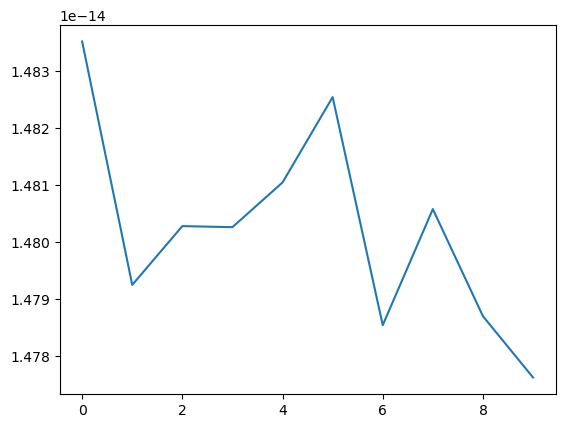

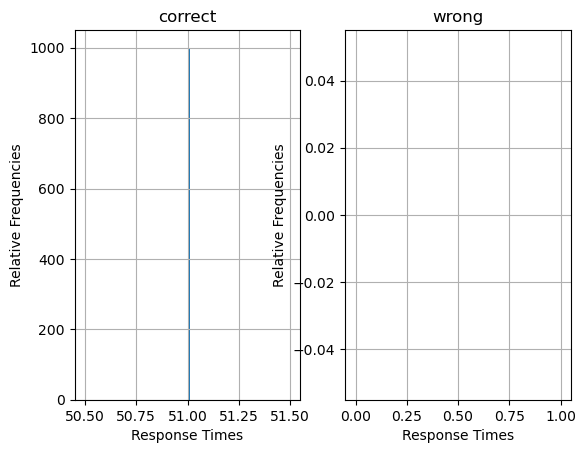

0.0
50
1.0


In [13]:
losses2=losses[-1000:]
plt.plot(np.arange(int(len(losses2)/100)), np.mean(np.split(losses2, int(len(losses2)/100)), axis=1))
plt.show()

neg=0

plot_dist(train_model, max_steps)
print(data_dist[neg,2])
print((data_dist[neg]==1.0).argmax())
print(data_dist[neg,(data_dist[neg]==1.0).argmax()])

## eval

In [55]:
model_drift=train_model.free_params[train_model.free_params_dict['drift']]
model_sigma=train_model.free_params[train_model.free_params_dict['sigma']]

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

z=z0
for t in range(max_steps):
    print(f"z at {t}: {z}")
    noise=np.random.random()-0.5
    print(f"plus noise:{noise}*sigma:{train_model.free_params[train_model.free_params_dict['sigma']]}")
    print(f"next should be:{z+model_drift+model_sigma*noise}")
    z = train_model.forward([z, np.random.random()-0.5])#for now lets not train z0
    #loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

    #losses.append(loss_function.forward([y, true]))

    #derivative=loss_function.back(None,-1)
    #print(derivative)
    #print(t)

    if z>=1 or (z<=0):
        print(f"final z: {z}")
        if t==0:
            too_fast+=1
            break
        if z>=1:
            target = np.mean(data_dist[0,t-1:t+1])
            size=size0
        else:
            target = 1- np.mean(data_dist[1,t-1:t+1])
            size=size1

        loss=loss_function_f(target, None, z)
        print("loss:",loss)

        #train_model.memory=[]
        derivative1= loss_function_b(target, None, z, None)
        derivative1/=size
        #derivative2/=size
        
        print(f"scaled derivatives of loss: {derivative1}")

        for t_back in range(t, 0-1, -1):
            print("t:",t_back)
            derivative1=train_model.back(derivative1, t_back, v=True)[0]

            '''if t_back<t:
                derivative2=train_model.back(derivative2, t_back, v=True)[0]'''

        break

    z_old=z

if t==max_steps-1:
    too_slow+=1

train_model.update(lr, v=True)

init params:
  sigma: 0.661324950487685
  drift: 0.003508636453002093

z at 0: 0.5
plus noise:0.4228292988820592*sigma:0.661324950487685
next should be:0.7831362016009225
z at 1: 0.6092538842935501
plus noise:-0.09719428727332402*sigma:0.661324950487685
next should be:0.5484855135278354
z at 2: 0.7267392769133466
plus noise:0.19393882519897054*sigma:0.661324950487685
next should be:0.8585044973386977
z at 3: 0.8694364689369102
plus noise:-0.45580751483086335*sigma:0.661324950487685
next should be:0.5715082232124769
z at 4: 0.7302139768726172
plus noise:0.20137941240412882*sigma:0.661324950487685
next should be:0.8668998432630189
z at 5: 0.7114598215565016
plus noise:-0.17429345006881247*sigma:0.661324950487685
next should be:0.5997038507724185
z at 6: 0.7663134657815197
plus noise:-0.08196965435301751*sigma:0.661324950487685
next should be:0.7156135246280199
z at 7: 0.9133641572232079
plus noise:0.2447092340136543*sigma:0.661324950487685
next should be:1.0787051157441692
final z: 1.131

# eval

In [41]:
#load new class
train_model=Node({name: value for name, value in zip(train_model.free_params_dict.keys(), train_model.free_params)}, train_model.constants, train_model.operation, train_model.derivative)             

In [46]:
z=z0
for t in range(max_steps):
    print(f"z at {t}: {z}")
    z = train_model.forward([z, np.random.random()-0.5])#for now lets not train z0

    #loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

    #losses.append(loss_function.forward([y, true]))

    #derivative=loss_function.back(None,-1)
    #print(derivative)
    #print(t)

    if z>=1 or (z<=0):
        print(f"final z: {z}")
        if t==0:
            too_fast+=1
            break
        if z>=1:
            target = np.mean(data_dist[0,t-1:t+1])
            size=size0
        else:
            target = 1- np.mean(data_dist[1,t-1:t+1])
            size=size1

        loss=loss_function_f(target, None, z)
        print("loss:",loss)

        #train_model.memory=[]
        derivative1 = loss_function_b(target, None, z, None)
        derivative1/=size
        
        print(f"scaled derivatives of loss: {derivative1}")

        for t_back in range(t, 0-1, -1):
            print("t:",t_back)
            derivative1=train_model.back(derivative1, t_back, v=True)[0]

            '''if t_back<t:
                derivative2=train_model.back(derivative2, t_back, v=True)[0]'''

        break

    z_old=z

if t==max_steps-1:
    too_slow+=1

train_model.update(lr, v=True)

z at 0: 0.5
z at 1: 0.6070393359135628
z at 2: 0.6800985582731345
z at 3: 0.5204173602099933
z at 4: 0.6470279876343232
z at 5: 0.8257784859943449
z at 6: 0.5271154112151036
z at 7: 0.6162464258624342
z at 8: 0.6689887758984004
z at 9: 0.3164328689778899
z at 10: 0.2491510997599096
final z: -0.0749760640933615
loss: 0.5777867691868274
scaled derivatives of loss: (-107.49760640933614, -2.9785064390550855e-05)
t: 10
gradient at 10: (-27.427719466318464, -107.49760640933614)
for inputs x [0.5, 0.2551472575294139]
t: 9
gradient at 9: (5.780440729874409, -27.427719466318464)
for inputs x [0.10865493171989835, -0.21075178113050386]
gradient at 9: (6.277255371395338e-06, -2.9785064390550855e-05)
for inputs x [0.10865493171989835, -0.21075178113050386]
t: 8
gradient at 8: (-1.0534762328773568, 5.780440729874409)
for inputs x [0.39626232879615275, -0.1822484274309384]
gradient at 8: (-1.1440199200192116e-06, 6.277255371395338e-06)
for inputs x [0.39626232879615275, -0.1822484274309384]
t: 7
gra

In [ ]:
def ddm_forward(constants, free_params, x):
    """
    expects x[0]=z and x[1]=noise
    """
    #print(f"{x[0]}+{x[1]}*{free_params[0]}+{free_params[1]}")
    return x[0]+x[1]*free_params[0]+free_params[1]

def ddm_backward(constants, free_params, x, df):
    """
    should give deriatives wrt z, drift and noise, nrt has to be somehow included in the loss function
    df (float): derivative of previous functions
    """
    #print(df, x)
    #return df*1, df*1, df*x[1] so far no z0
    return df*x[1], df*1

def mean_l2_forward(constants, __, x):
    return 1/2*(constants - (1/2 * x[0] + 1/2 * x[1]))**2

def mean_l2_backward(constants, __, x, ___):
    df = -1/2*constants + 1/4*x[0] + 1/4*x[1]
    return df, df

        
    def forward(self,x):
        self.memory.append(x)
        return self.operation(self.constants, self.free_params, x)
    
    def back(self, df, t=None, v=False):
        """
        params:
            df (float): gradient of the next operation aka derivative of all that happens after this node
        """
        x=self.memory[t]
        #x=self.memory.pop()
        self.gradients.append(self.derivative(self.constants, self.free_params, x, df))
        if v==True:
            print(f"gradient at {t}: {self.gradients[-1]}")
            print(f"for inputs x",x)
        return self.gradients[-1]
    
    def update(self, lr, v=False):
        """
        terrible efficiency, todo: use dict only for mapping index to name and work on an array
        """
        #for key in np.arange(len(self.free_params)):
        #print(self.gradients)
        self.free_params-=lr*np.sum(self.gradients, axis=0)
        if v:
            print("updates:",-lr*np.sum(self.gradients, axis=0))
            print("individual updates: -",self.gradients)
        self.gradients=[]
        
"""
f = 1/2(1 - (1/2 x0 + 1/2 x1))**2
f = 1/2(1 - 1/2x0 - 1/2x1)**2

g(h) = 1/2h**2
h(x0, x1) = 1 - 1/2x0 - 1/2x1

df/dx = dh/dx (x) * dg/dx (h)

dh/dx0 = - 1/2

dg/dx = h

df/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)
        = - 1/2 - 1/4 x0 - 1/4 x1

df/dx0 = 
"""

In [14]:
print(data_dist[0,2])
print((data_dist[0]==1.0).argmax())
print(data_dist[0,(data_dist[0]==1.0).argmax()])

0.0
25
1.0


In [16]:
def generate_data_t_noiseless(model, max_steps, z0=0.5, n=1000):
    data=np.zeros((n,2))
    
    for i in range(n):
        z=z0
        
        run=True
        t=0
        while t<=max_steps:
            t+=1
            z = model.forward([z, 0])#np.random.random()-0.5])
            if z>=1:
                data[i]=[t,1]
                break
                
            elif z<=0:
                data[i]=[t,-1]
                break

    return data

def plot_dist_noiseless(train_model, max_steps):
    predictions=generate_data_t_noiseless(train_model, max_steps, n=1000)
    df=pd.DataFrame()
    df["response"]=predictions[:,1]
    df["rt"]=predictions[:,0]
    ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
    ddm.log=df
    #print(df)
    ddm.plot_histogram(conditions=[])

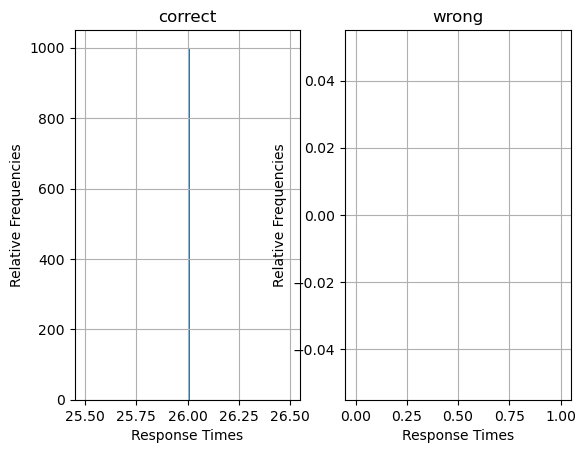

In [18]:
plot_dist_noiseless(train_model, max_steps)

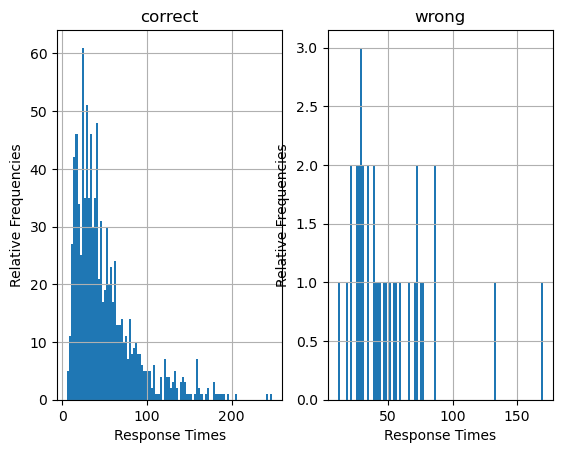

In [13]:
plot_dist(ddm_net, max_steps)

     response   rt
0        -1.0  7.0
1        -1.0  7.0
2        -1.0  5.0
3        -1.0  5.0
4        -1.0  4.0
..        ...  ...
995      -1.0  4.0
996      -1.0  8.0
997      -1.0  7.0
998      -1.0  8.0
999      -1.0  5.0

[1000 rows x 2 columns]


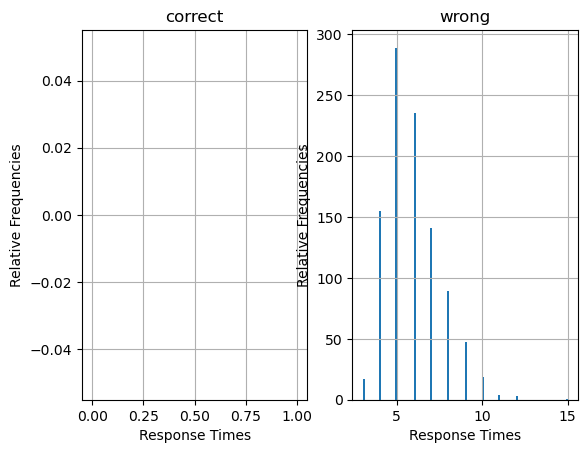

In [6]:
predictions=generate_data_t(train_model, max_steps, n=1000)
df=pd.DataFrame()
df["response"]=predictions[:,1]
df["rt"]=predictions[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

## kinda working verion

      response     rt
0          1.0   84.0
1          1.0   54.0
2          1.0   27.0
3          1.0   27.0
4          1.0   55.0
...        ...    ...
9995       1.0  126.0
9996       1.0   17.0
9997       1.0   17.0
9998       1.0   87.0
9999       1.0   55.0

[10000 rows x 2 columns]


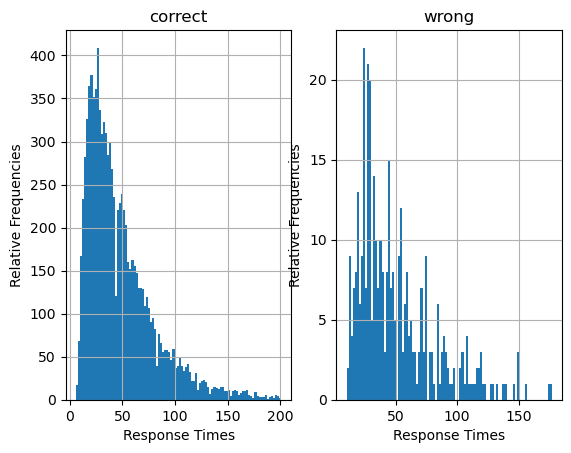

1.0
original params:
  sigma: 0.2
  drift: 0.01

init params:
  sigma: 0.49457472638676403
  drift: -0.24808746638623103



 11%|███████▉                                                                 | 10900/100000 [00:01<00:12, 6879.19it/s]

loss: 0.31244632198425987
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.4785579210842701
  drift: 0.05200103683224705



 20%|██████████████▋                                                          | 20140/100000 [00:03<00:09, 8113.99it/s]

loss: 0.3037681497539333
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.45937340686145023
  drift: 0.05022415269087449



 31%|██████████████████████▋                                                  | 31140/100000 [00:05<00:10, 6511.37it/s]

... (11 outputs left out)

 91%|██████████████████████████████████████████████████████████████████▎      | 90808/100000 [00:15<00:01, 6147.47it/s]

loss: 0.2577416930969051
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.4140204857770888
  drift: 0.046538707313613384



100%|████████████████████████████████████████████████████████████████████████| 100000/100000 [00:17<00:00, 5637.51it/s]


loss: 0.2579619812046204
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.4153782347479726
  drift: 0.04637356150028719

wasted_runs 0


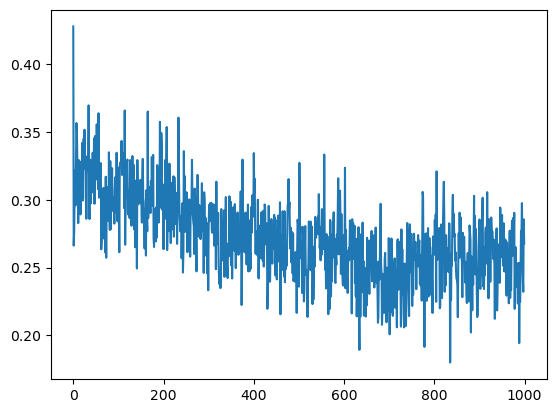

In [5]:
# 1st: there is gotta be a bug or a bias I did not understand at all: drift always becomes negative! 
# -> bug found: noise was not zero centered

# !!forgot to use cumulative dist!!

# 2nd: try using the normalized diff p_t,true-p_t,false
# 3rd: try our using ce of cheated distribution over batch
# misc: show ce

# generate dataset over t
z0=0.5
sigma=0.2
drift=0.01
max_steps=200
epochs=100000
lr=1

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=10000)
#print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

# (response, rt)
data_dist=np.zeros((2, max_steps))
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))

data_dist[0,:]=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
size0=data_dist[0].sum()
data_dist[0,:]/=np.max(data_dist[0,:])


data_dist[1,:]=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]
size1=data_dist[1].sum()

data_dist[1,:]/=np.max(data_dist[1,:])

print(data_dist[1,:].max())




print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backward)

loss_function_f=mean_l2_forward#
loss_function_b=mean_l2_backward#Node({},{},l2_forward, l2_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]

too_fast=0
too_slow=0
good_runs=0

for epoch in tqdm(range(epochs)):
    z=z0
    z_old=z0
    for t in range(max_steps):
        z = train_model.forward([z, np.random.random()-0.5])#for now lets not train z0

        #loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

        #losses.append(loss_function.forward([y, true]))
        
        #derivative=loss_function.back(None,-1)
        #print(derivative)
        #print(t)
        
        if z>=1 or (z<=0):
            if t==0:
                too_fast+=1
                break
            if z>=1:
                target = np.mean(data_dist[0,t-1:t+1])
                size=size0
            else:
                target = 1- np.mean(data_dist[1,t-1:t+1])
                size=size1
                
            losses.append(loss_function_f(target, None, (z_old, z)))
            
            #train_model.memory=[]
            derivative1, derivative2 = loss_function_b(target, None, (z_old, z), None)
            derivative1/=size
            derivative2/=size
            
            for t_back in range(t, 0-1, -1):
                
                derivative1=train_model.back(derivative1, t_back)[0]
                
                if t_back<t:
                    derivative2=train_model.back(derivative2, t_back)[0]
                   
            good_runs+=1
            break
                
        z_old=z
        
    if t==max_steps-1:
        too_slow+=1
        
    train_model.update(lr)
    
    if not (epoch+1)%(epochs/10):
        print("loss:", np.mean(losses[-int(epochs/10):]))
        print("n too fast:", too_fast)
        print("n too slow:", too_slow)
        # self-check if insane
        print("n good_runs:", good_runs)
        too_fast=0
        too_slow=0
        good_runs=0
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

wasted_runs=epochs-len(losses)
if (len(losses)%100):
    losses = losses[:-(len(losses)%100)]
losses=np.array(losses)
print("wasted_runs",wasted_runs)
plt.plot(np.arange(int(len(losses)/100)), np.mean(np.split(losses, int(len(losses)/100)), axis=1))
plt.show()

# End

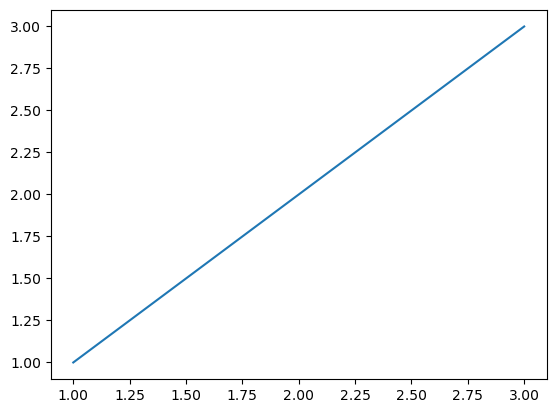

In [1]:
import matplotlib.pyplot as plt
plt.plot([1,2,3], [1,2,3])
plt.show()

## MSE(z, p(z|t)) for all t
p(z|t) unknown, but could be approximated by argmax_z(p(z>=1)) which will be assumed to be directly in the middle of the two

- todo: plot average trajectory

[[ 28.  -1.]
 [ 51.   1.]
 [ 62.   1.]
 ...
 [201.   1.]
 [ 60.   1.]
 [ 72.  -1.]]
wrongs: 3402
      response     rt
0         -1.0   28.0
1          1.0   51.0
2          1.0   62.0
3          1.0   99.0
4         -1.0  127.0
...        ...    ...
9995      -1.0   51.0
9996       1.0   83.0
9997       1.0  201.0
9998       1.0   60.0
9999      -1.0   72.0

[10000 rows x 2 columns]


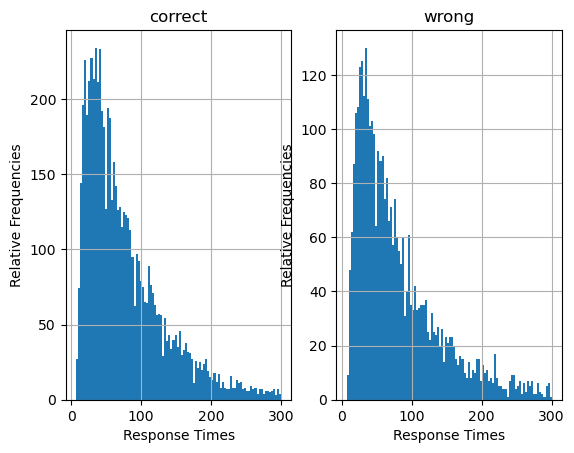

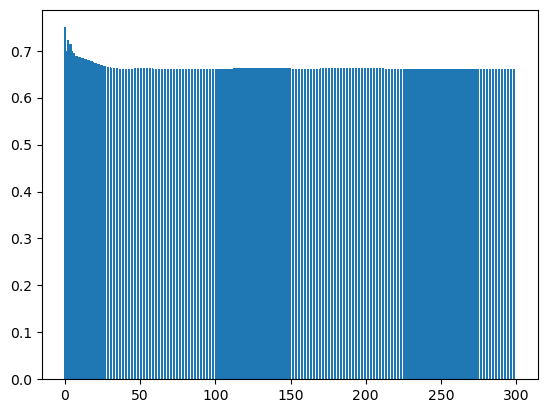

In [3]:
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless, Node, ddm_forward, ddm_backward
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

z0=0.5
sigma=0.2
drift=0.002
max_steps=300
epochs=10000000#-00
n_data=10000

sample_size=n_data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]

print("wrongs:",(df["response"]==-1).sum())

ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

target=torch.zeros(2*max_steps)
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))
corrects=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
wrongs=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]

'''for i in range(max_steps):
    corrects[i]=corrects[:i+1].sum()
    wrongs[i]=wrongs[:i+1].sum()'''

corrects_old=corrects
wrongs_old=wrongs
cum_old=corrects.sum()+wrongs.sum()

corrects=gaussian_filter1d(corrects, 6, mode="constant")
wrongs=gaussian_filter1d(wrongs, 6, mode="constant")


corrects=np.cumsum(corrects)
wrongs=np.cumsum(wrongs)

#print(cum)
target=torch.from_numpy(corrects/(corrects+wrongs)).nan_to_num(nan=0.5)#should later be replaced by completely ignoring early samples

plt.bar(np.arange(len(target)), target)
plt.show()
#target=np.cumsum(target)
#plt.bar(np.arange(len(target)), target)
#plt.show()

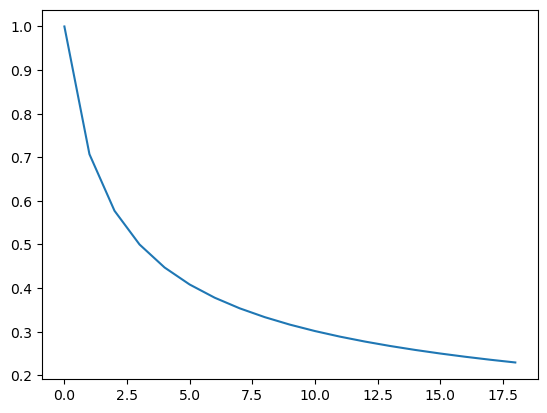

In [14]:
x=np.zeros(19)
for i in range(1,20):
    x[i-1]=i**(-1/2)
plt.plot(np.arange(19), x)
plt.show()

f = 1/2 (y-t)^2
df/dy = (y - t)*1

f = 2 (y-t)^1/2

df/dy = (y-t)^(-1/2) *1

In [5]:
torch.sqrt(torch.tensor(-0.5))

tensor(nan)

original drift: 0.002, sigma: 0.2


  0%|                                                                                          | 0/400 [00:00<?, ?it/s]

loss: 1.1327510827650493
sigma: 0.2622047490049018
drift: 0.0006533214056270128


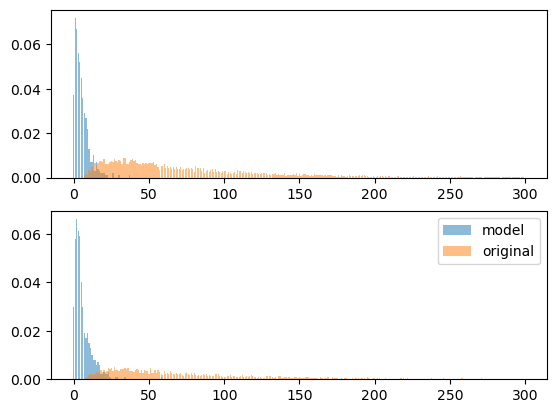

 10%|████████                                                                         | 40/400 [06:02<57:04,  9.51s/it]

loss: 2.647146588166966
sigma: 0.26218095787565004
drift: 0.0006600620623670448


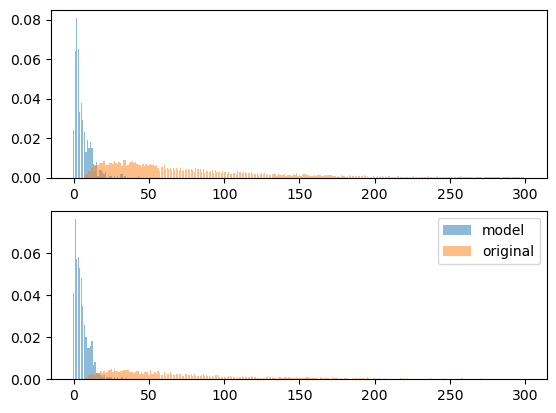

 20%|████████████████▏                                                                | 80/400 [12:17<48:03,  9.01s/it]

loss: 2.584071139879472
sigma: 0.26216432653784977
drift: 0.0006622425150637437


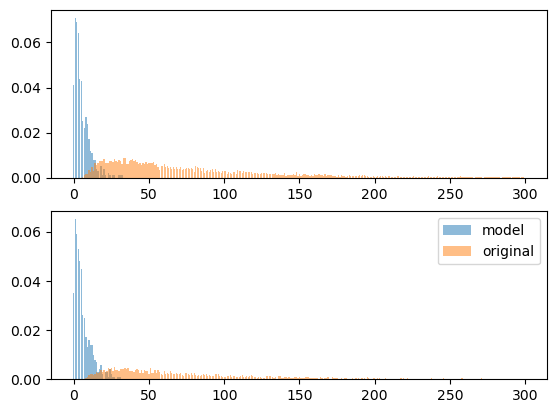

 30%|████████████████████████                                                        | 120/400 [18:32<44:45,  9.59s/it]

loss: 2.685068445574771
sigma: 0.26215257647543994
drift: 0.0006641741596357797


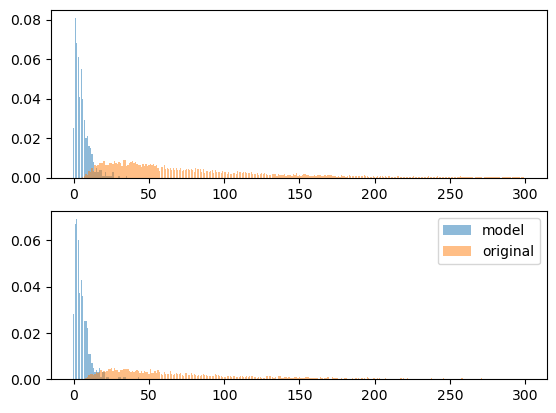

 40%|████████████████████████████████                                                | 160/400 [24:44<36:03,  9.02s/it]

loss: 4.431500753675315
sigma: 0.2621443905749417
drift: 0.0006601432071602257


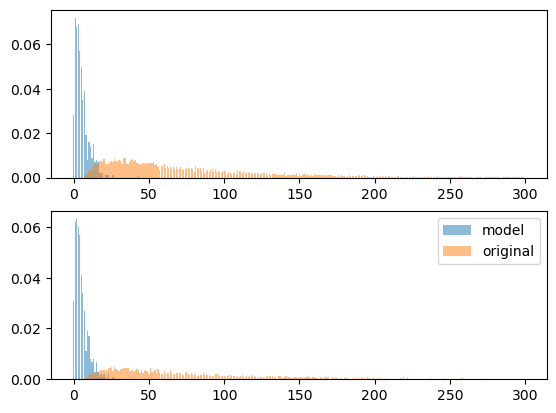

 50%|████████████████████████████████████████                                        | 200/400 [30:59<30:43,  9.22s/it]

loss: 3.71798725503556
sigma: 0.2621386850302847
drift: 0.0006622697286999188


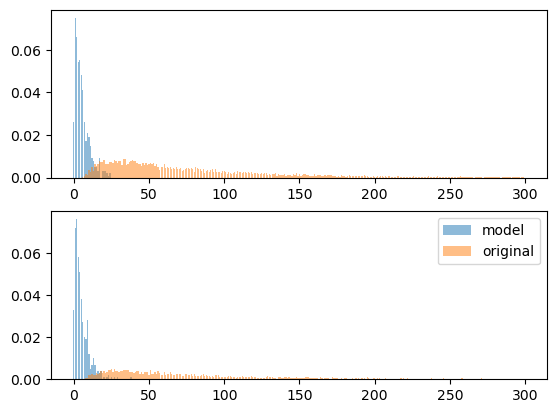

 60%|████████████████████████████████████████████████                                | 240/400 [37:11<23:28,  8.80s/it]

loss: 3.4058003224432674
sigma: 0.26213470398864763
drift: 0.0006631497319455629


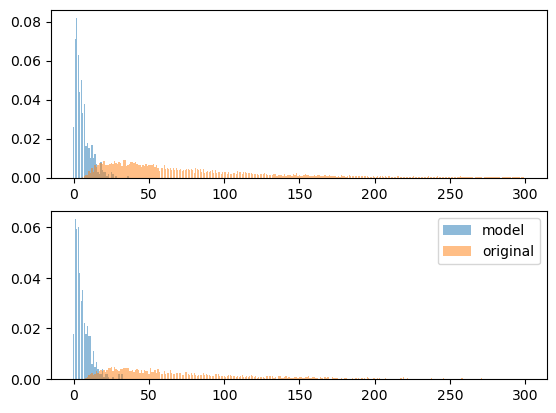

 70%|████████████████████████████████████████████████████████                        | 280/400 [43:28<18:38,  9.32s/it]

loss: 2.476083638270644
sigma: 0.2621319049185534
drift: 0.0006630052818620911


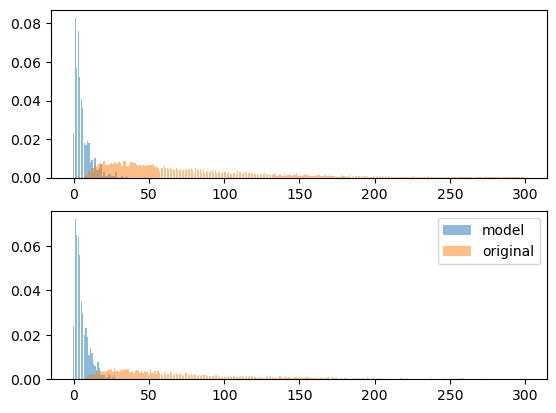

 80%|████████████████████████████████████████████████████████████████                | 320/400 [49:44<12:23,  9.29s/it]

loss: 1.6921514647198876
sigma: 0.26212995534438005
drift: 0.0006633495472671288


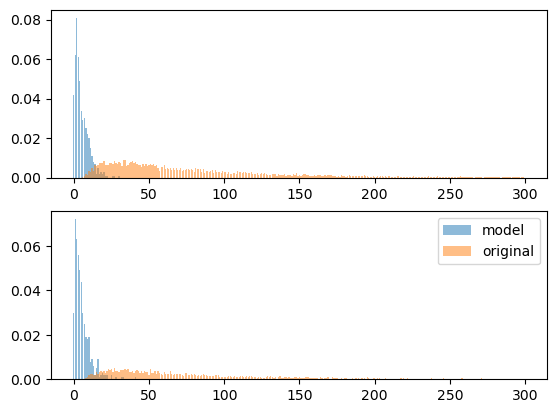

 90%|████████████████████████████████████████████████████████████████████████        | 360/400 [55:58<05:55,  8.88s/it]

loss: 2.7053809717098187
sigma: 0.2621285676971194
drift: 0.0006633332129563127


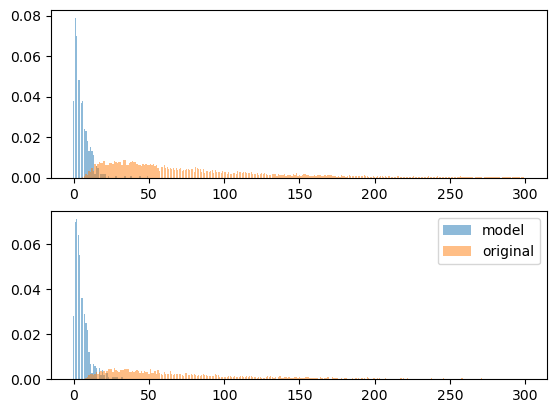

100%|██████████████████████████████████████████████████████████████████████████████| 400/400 [1:02:08<00:00,  9.32s/it]


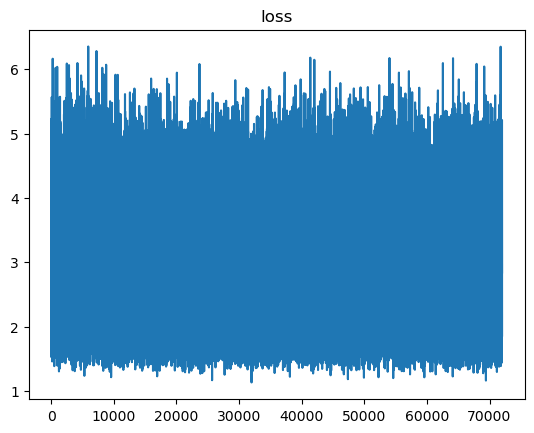

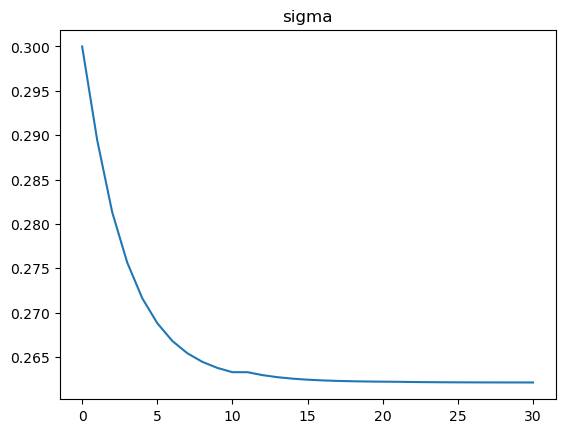

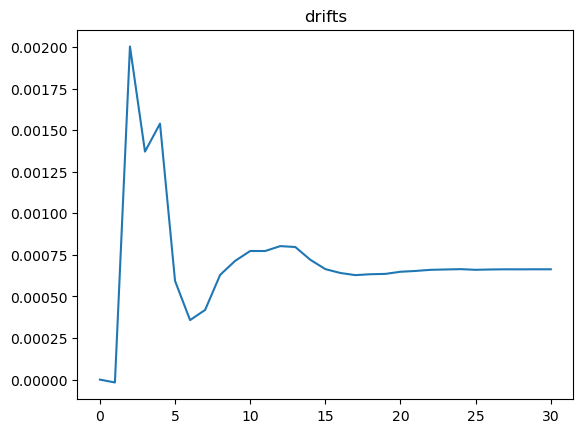

In [20]:
# wtf why so slow?? also should use l1/2 or sth as loss

import torch
from tqdm import tqdm

epochs=400#10000000#-00
batchsize=100
lr=0.0000001#100.0
annealing=True

n_data=10000
initial_drift=0.0
initial_sigma=0.3

print(f"original drift: {drift}, sigma: {sigma}")
sample_size=int(n_data/10)

def l_sqrt_loss(output, target):
    diff=output-target
    positives=2*torch.sqrt(diff[diff>0])
    negatives=2*torch.sqrt(-diff[diff<0])
    #note, that for diff=0 there will be no gradient, which conveniently is the point where |y-t|^(1/2) is minimized
    loss=torch.mean(torch.concat((positives,negatives)))
    return loss


class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.max_steps=max_steps
        self.layer = torch.nn.Linear(1, 1)
        self.noise = torch.distributions.normal.Normal(torch.Tensor([0.0]).double(), 1)
        
    def forward(self, z):
        #t+=1
        inp = self.noise.sample()
        inp=inp.double()
        output=self.layer(inp)
        z=output+z#torch.sum(torch.concat([output,z]), dtype=torch.float64)
        #z=output+z
        return z#, t
        '''
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)'''
        
    def inference(self, z, t):
        with torch.no_grad():
            inp = self.noise.sample()
            inp=inp.double()
            output=self.layer(inp)
            z=output+z#torch.sum(torch.concat([output,z]), dtype=torch.float64)
            #z=output+z
            if z<=0 or z>=1 or t==self.max_steps-1:
                return z, t
            else:
                return self.inference(z, t+1)
#continue
'''
model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)

model=model.double()

loss_function = l_sqrt_loss#CrossEntropyLoss()
losses=[]
sigmas=[]
drifts=[]'''

#optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)
                    
for i in tqdm(range(epochs)):
    
    if not (i)%int(epochs/10):
        try:
            print("loss:", np.mean(losses[-1]))
        except Exception:
            pass

        sigmas.append(model.layer.weight.data[0,0].detach().clone())
        drifts.append(model.layer.bias.data[0].detach().clone())

        print(f"sigma: {sigmas[-1]}")
        print(f"drift: {drifts[-1]}")

        y=np.zeros((2,max_steps))
        
        for _ in range(sample_size):
            z,t=model.inference(0.5,0)
            if z>0.5:
                y[0,t]+=1
            else:
                y[1,t]+=1
                
            
        cum=sample_size
        fig, axs = plt.subplots(2)
        axs[0].bar(range(max_steps), y[0]/cum, alpha=0.5, label="model")
        axs[1].bar(range(max_steps), y[1]/cum, alpha=0.5, label="model")

        axs[0].bar(range(max_steps), corrects_old/cum_old, alpha=0.5, label="original")
        axs[1].bar(range(max_steps), wrongs_old/cum_old, alpha=0.5, label="original")
        plt.legend()
        plt.show()

        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.7   
                
    optimizer.zero_grad()
    
    for _ in range(batchsize):
        y=torch.zeros(max_steps).double()
        z=torch.Tensor([0.5]).double()
        for t in range(max_steps):
            z = model(z)
            y[t] = z.clone()

        #y=torch.cumsum(y, 1)

        #should I detach?
        #y=y/(sample_size/n_data)#torch.sum(y)

        #y=y/sample_size#y.sum()
        loss=loss_function(y, target)
        losses.append(loss.item())

        loss.backward()
        
    optimizer.step()


name = f"l_half_{lr}_{initial_sigma}_{initial_drift}"
torch.save(model.state_dict(), name+".pt")
np.save("losses_"+name, np.array(losses))
np.save("drifts_"+name, np.array(drifts))
np.save("sigmas_"+name, np.array(sigmas))
                    
plt.plot(range(len(losses)), losses)
plt.title("loss")
plt.show()
plt.plot(range(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(range(len(drifts)), drifts)
plt.title("drifts")
plt.show()

original drift: 0.001, sigma: 0.2


  0%|                                                                                          | 0/160 [00:00<?, ?it/s]

sigma: 0.30000001192092896
drift: 0.0


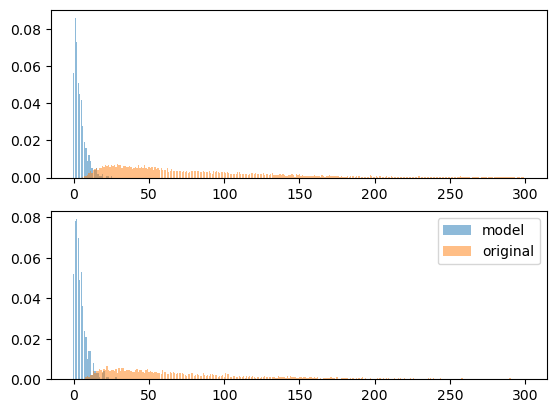

 10%|████████                                                                         | 16/160 [03:17<28:43, 11.97s/it]

loss: 19.521492496804193
sigma: 0.2810848017652417
drift: 0.0030362690320099926


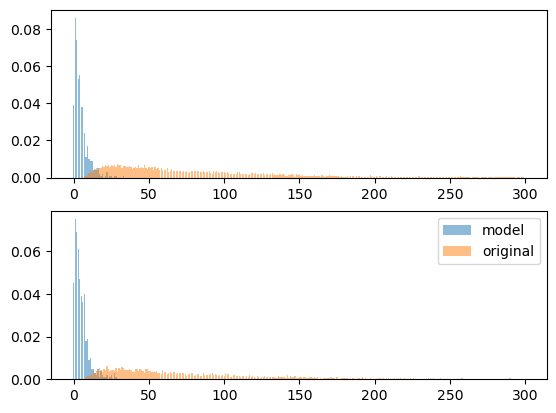

 20%|████████████████▏                                                                | 32/160 [06:35<25:47, 12.09s/it]

loss: 13.53340546984967
sigma: 0.26818943428567454
drift: 0.002776341610464223


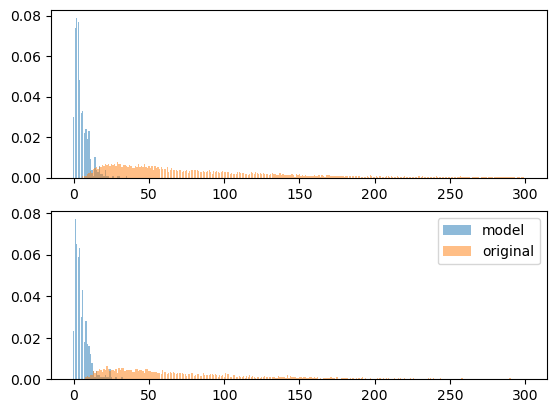

 30%|████████████████████████▎                                                        | 48/160 [09:51<22:19, 11.96s/it]

loss: 3.1636635842276024
sigma: 0.25964459932114115
drift: 0.002773483274303537


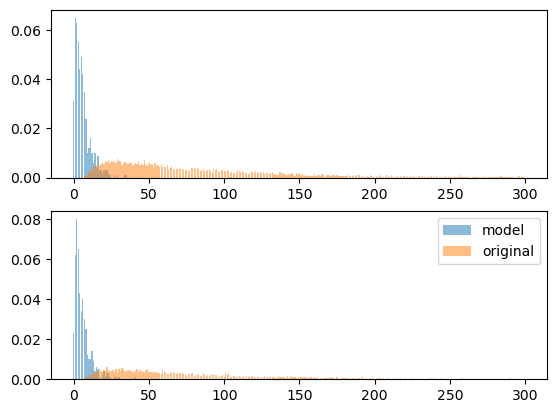

 40%|████████████████████████████████▍                                                | 64/160 [13:07<19:16, 12.05s/it]

loss: 12.765684261691481
sigma: 0.2537871842938409
drift: 0.003130427011290364


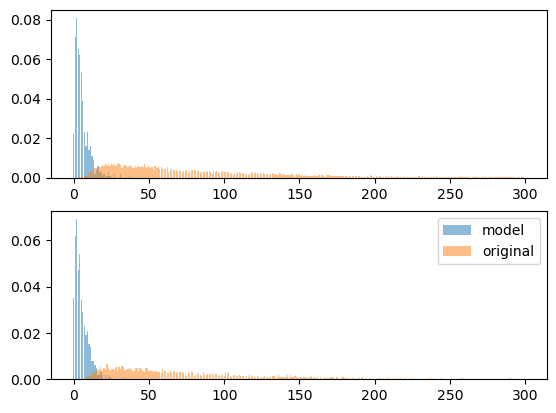

 50%|████████████████████████████████████████▌                                        | 80/160 [15:36<13:33, 10.17s/it]

loss: 2.243092758123267
sigma: 0.24969455827486473
drift: 0.001953542375387703


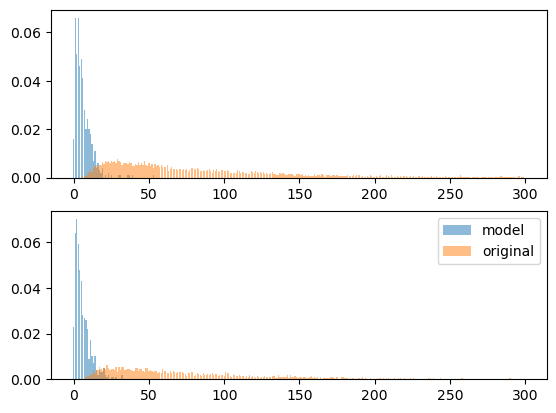

 60%|████████████████████████████████████████████████▌                                | 96/160 [19:00<14:01, 13.14s/it]

loss: 32.28006178595348
sigma: 0.2468113684805077
drift: 0.0029224377873719484


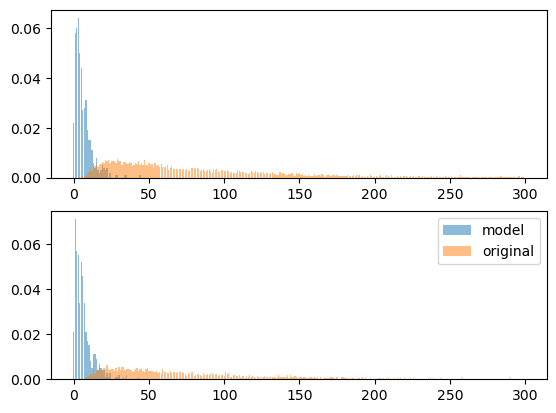

 70%|████████████████████████████████████████████████████████                        | 112/160 [23:05<12:04, 15.09s/it]

loss: 5.03957053436869
sigma: 0.24478333956671364
drift: 0.0023362007129149633


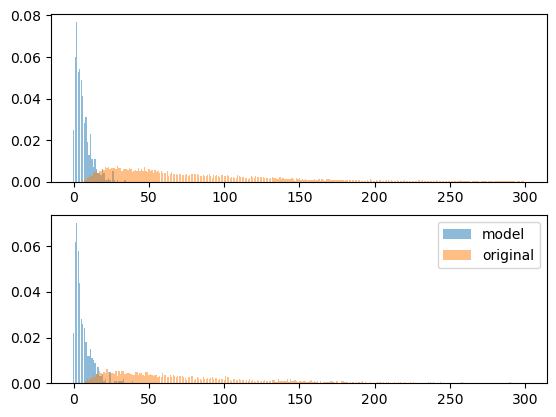

 80%|████████████████████████████████████████████████████████████████                | 128/160 [27:10<07:54, 14.82s/it]

loss: 3.5807293699269493
sigma: 0.24348189075954532
drift: 0.00168064644929637


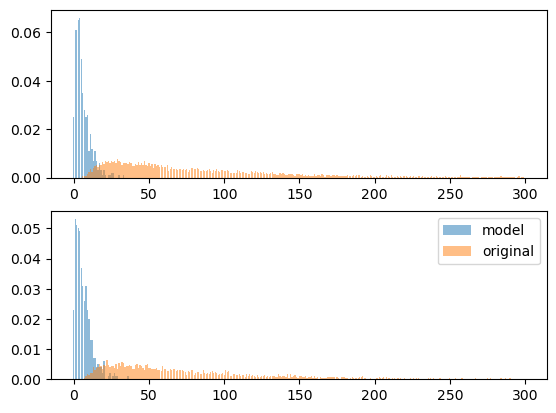

 90%|████████████████████████████████████████████████████████████████████████        | 144/160 [31:20<04:13, 15.86s/it]

loss: 4.286773924129599
sigma: 0.24255259725191078
drift: 0.0022278818584392087


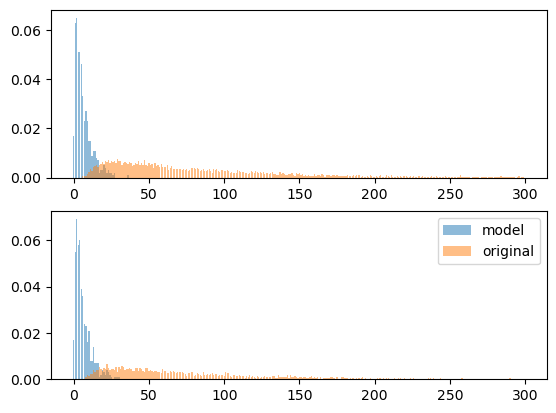

100%|████████████████████████████████████████████████████████████████████████████████| 160/160 [35:25<00:00, 13.29s/it]


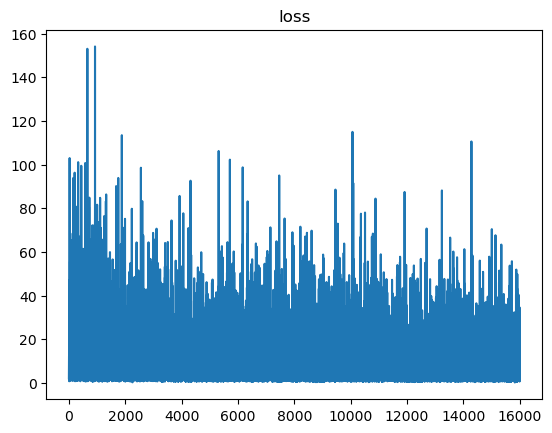

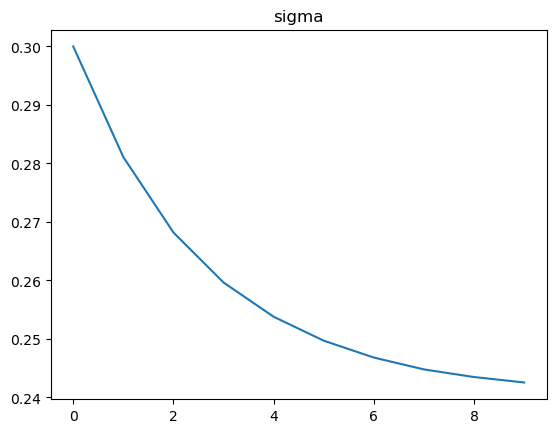

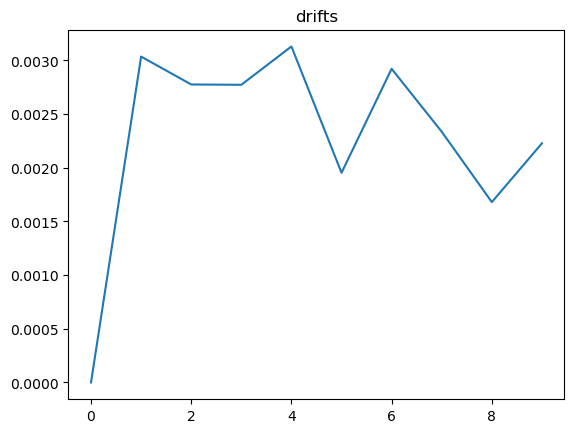

In [27]:
# wtf why so slow?? also should use l1/2 or sth as loss

import torch
from tqdm import tqdm

epochs=160#10000000#-00
batchsize=100
lr=0.0000001#100.0
annealing=True

n_data=10000
initial_drift=0.0
initial_sigma=0.3

print(f"original drift: {drift}, sigma: {sigma}")
sample_size=int(n_data/10)

class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.max_steps=max_steps
        self.layer = torch.nn.Linear(1, 1)
        self.noise = torch.distributions.normal.Normal(torch.Tensor([0.0]).double(), 1)
        
    def forward(self, z):
        #t+=1
        inp = self.noise.sample()
        inp=inp.double()
        output=self.layer(inp)
        z=output+z#torch.sum(torch.concat([output,z]), dtype=torch.float64)
        #z=output+z
        return z#, t
        '''
        if z<=0 or z>=1 or t==max_steps:
            return z, t
        else:
            return self.__call__(z, t)'''
        
    def inference(self, z, t):
        with torch.no_grad():
            inp = self.noise.sample()
            inp=inp.double()
            output=self.layer(inp)
            z=output+z#torch.sum(torch.concat([output,z]), dtype=torch.float64)
            #z=output+z
            if z<=0 or z>=1 or t==self.max_steps-1:
                return z, t
            else:
                return self.inference(z, t+1)

model=DDMTorch()
model.layer.weight.data.fill_(initial_sigma)
model.layer.bias.data.fill_(initial_drift)

model=model.double()

loss_function = torch.nn.MSELoss()#CrossEntropyLoss()
losses=[]
sigmas=[]
drifts=[]

optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.5)
for i in tqdm(range(epochs)):
    
    if not (i)%int(epochs/10):
        try:
            print("loss:", np.mean(losses[-1]))
        except Exception:
            pass

        sigmas.append(model.layer.weight.data[0,0].detach().clone())
        drifts.append(model.layer.bias.data[0].detach().clone())

        print(f"sigma: {sigmas[-1]}")
        print(f"drift: {drifts[-1]}")

        y=np.zeros((2,max_steps))
        
        for _ in range(sample_size):
            z,t=model.inference(0.5,0)
            if z>0.5:
                y[0,t]+=1
            else:
                y[1,t]+=1
                
            
        cum=sample_size
        fig, axs = plt.subplots(2)
        axs[0].bar(range(max_steps), y[0]/cum, alpha=0.5, label="model")
        axs[1].bar(range(max_steps), y[1]/cum, alpha=0.5, label="model")

        axs[0].bar(range(max_steps), corrects_old/cum_old, alpha=0.5, label="original")
        axs[1].bar(range(max_steps), wrongs_old/cum_old, alpha=0.5, label="original")
        plt.legend()
        plt.show()

        if annealing:
            for group in optimizer.param_groups:
                group['lr'] *= 0.7   
                
    optimizer.zero_grad()
    
    for _ in range(batchsize):
        y=torch.zeros(max_steps).double()
        z=torch.Tensor([0.5]).double()
        for t in range(max_steps):
            z = model(z)
            y[t] = z.clone()

        #y=torch.cumsum(y, 1)

        #should I detach?
        #y=y/(sample_size/n_data)#torch.sum(y)

        #y=y/sample_size#y.sum()
        loss=loss_function(y, torch.ones(len(y)).double())#target)
        losses.append(loss.item())

        loss.backward()
        
    optimizer.step()



            
plt.plot(range(len(losses)), losses)
plt.title("loss")
plt.show()
plt.plot(range(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(range(len(drifts)), drifts)
plt.title("drifts")
plt.show()

In [26]:
torch.save(model.state_dict(), f"p_based1_{sigma}_{drift}.pt")

In [8]:
list(model.parameters())

[Parameter containing:
 tensor([[-0.4684]], requires_grad=True),
 Parameter containing:
 tensor([0.1934], requires_grad=True)]

In [37]:
z=torch.tensor([-0.0757])
z=(z-(z.detach())-1)*-1
print(z)
y[1,1]+=z[0]

tensor([1.])


In [11]:
df["plausible"]=0
df

,response,rt,plausible
0,-1.0,33.0,0
1,1.0,96.0,0
2,-1.0,50.0,0
3,1.0,297.0,0
4,1.0,87.0,0
...,...,...,...
9995,1.0,167.0,0
9996,1.0,39.0,0
9997,1.0,27.0,0
9998,-1.0,102.0,0


## double precision

In [49]:
target[5]

tensor(0.5000, dtype=torch.float64)

In [6]:
class DDMTorch(torch.nn.Module):
    
    def __init__(self, max_steps=300):
        super().__init__()
        self.layer = torch.nn.Linear(1, 1)
        
    def forward(self, z):
        #t+=1
        inp = torch.rand(1)-0.5
        print("here",inp)
        inp=inp.double()
        print(inp)
        output=self.layer(z)
        print(output)
        print(z)
        z=output+z#torch.sum(torch.concat([output,z]), dtype=torch.float64)
        print(z)
        #z=output+z
        return z#z#, t
model=DDMTorch().double()

z=torch.Tensor([5.0]).double()
y=torch.zeros(5).double()

for i in range(5):
    z=model(z)
    y[i]=z.clone()
    
loss=loss_function(y, target[5])
loss.backward()

here tensor([-0.0128])
tensor([-0.0128], dtype=torch.float64)
tensor([4.5991], dtype=torch.float64, grad_fn=<ViewBackward0>)
tensor([5.], dtype=torch.float64)
tensor([9.5991], dtype=torch.float64, grad_fn=<AddBackward0>)
here tensor([0.2006])
tensor([0.2006], dtype=torch.float64)
tensor([8.1826], dtype=torch.float64, grad_fn=<ViewBackward0>)
tensor([9.5991], dtype=torch.float64, grad_fn=<AddBackward0>)
tensor([17.7817], dtype=torch.float64, grad_fn=<AddBackward0>)
here tensor([0.1873])
tensor([0.1873], dtype=torch.float64)
tensor([14.5585], dtype=torch.float64, grad_fn=<ViewBackward0>)
tensor([17.7817], dtype=torch.float64, grad_fn=<AddBackward0>)
tensor([32.3401], dtype=torch.float64, grad_fn=<AddBackward0>)
here tensor([0.2163])
tensor([0.2163], dtype=torch.float64)
tensor([25.9023], dtype=torch.float64, grad_fn=<ViewBackward0>)
tensor([32.3401], dtype=torch.float64, grad_fn=<AddBackward0>)
tensor([58.2425], dtype=torch.float64, grad_fn=<AddBackward0>)
here tensor([0.1832])
tensor([0